# Did the IL&FS Default Trigger a Structural Shift in Option Pricing and Hedging?

**Evidence from NIFTY and BANKNIFTY Index Options**

The empirical design compares NIFTY and BANKNIFTY European index options before
and after the IL&FS default event date of 04 September 2018.


In [ ]:
# ================================================================
# SECTION 1 - LOAD DATASET
# ================================================================


from __future__ import annotations

import math
import os
import platform
import time
import warnings
from pathlib import Path
from typing import Iterable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import seaborn as sns
import statsmodels.api as sm
from IPython.display import display
from scipy.optimize import brentq
from scipy.stats import levene, mannwhitneyu, norm, normaltest, ttest_ind

warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 180)
pd.set_option("display.float_format", lambda value: f"{value:,.6f}")

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette="colorblind",
    rc={
        "figure.figsize": (11, 6),
        "axes.titlesize": 14,
        "axes.labelsize": 11,
        "legend.frameon": False,
        "axes.spines.right": False,
        "axes.spines.top": False,
    },
)

NOTEBOOK_RUN_STARTED = pd.Timestamp.now()
print(f"Notebook run started: {NOTEBOOK_RUN_STARTED:%Y-%m-%d %H:%M:%S}")
print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__}")
print(f"numpy: {np.__version__}")
print(f"scipy: {scipy.__version__}")
print(f"statsmodels: {sm.__version__}")


Notebook run started: 2026-07-29 11:55:50
Python: 3.13.5
pandas: 2.2.3
numpy: 2.1.3
scipy: 1.15.3
statsmodels: 0.14.4


In [2]:
# ---------------------------------------------------------------
# Project paths and constants
# ---------------------------------------------------------------
# All outputs are written to separate folders. The original validated
# dataset remains unchanged.

BASE_DIR = Path.cwd()
INPUT_FILE = BASE_DIR / "analysis_dataset_validation_complete.csv"

OUTPUT_DATA_FILE = BASE_DIR / "analysis_dataset_final.csv"
FINAL_REVIEW_REPORT_FILE = BASE_DIR / "final_review_report.md"
FIGURE_DIR = BASE_DIR / "figures"
TABLE_DIR = BASE_DIR / "tables"

FIGURE_DIR.mkdir(exist_ok=True)
TABLE_DIR.mkdir(exist_ok=True)

EVENT_DATE = pd.Timestamp("2018-09-04")
EXPECTED_ROWS = 248_227
RISK_FREE_DAYS_PER_YEAR = 365.0

# Brent root search bounds for annualised implied volatility.
# 0.01% to 500% is wide enough for stressed option markets while still
# rejecting nonsensical roots.
IV_LOWER_BOUND = 1.0e-4
IV_UPPER_BOUND = 5.0

# Moneyness is supplied as a validated continuous ratio. For grouped
# dissertation tables, a temporary reporting band is useful. The raw
# moneyness column is not replaced or recoded.
ATM_LOWER = 0.97
ATM_UPPER = 1.03
FOCUSED_EVENT_WINDOWS = [5, 10, 20]
ROLLING_DAILY_WINDOW = 5
ROLLING_WEEKLY_WINDOW = 4

REQUIRED_COLUMNS = [
    "date",
    "index",
    "expiry",
    "strike",
    "option_type",
    "spot_price",
    "future_price",
    "option_price",
    "option_open",
    "option_high",
    "option_low",
    "option_close",
    "option_settlement_price",
    "volume",
    "turnover",
    "open_interest",
    "change_in_oi",
    "india_vix",
    "risk_free_rate",
    "risk_free_rate_percent",
    "days_to_expiry",
    "time_to_expiry_days",
    "trading_days_to_expiry",
    "time_to_expiry_years",
    "event_date",
    "event_dummy",
    "days_from_event",
    "weeks_from_event",
    "pre_post_period",
    "moneyness",
    "log_moneyness",
    "daily_return_spot",
    "log_return_spot",
    "rolling_20d_volatility",
    "year",
    "month",
    "week",
    "day_of_week",
    "is_month_end",
    "spot_open",
    "spot_high",
    "spot_low",
    "shares_traded",
    "spot_turnover_inr_cr",
    "future_expiry",
    "future_match_type",
    "future_open",
    "future_high",
    "future_low",
    "future_close",
    "future_settlement_price",
    "future_days_to_expiry",
    "instrument",
    "india_vix_open",
    "india_vix_high",
    "india_vix_low",
    "india_vix_adj_close",
]

DATE_COLUMNS = ["date", "expiry", "event_date", "future_expiry"]

print(f"Working directory: {BASE_DIR}")
print(f"Input dataset: {INPUT_FILE.name}")
print(f"Figure directory: {FIGURE_DIR}")
print(f"Table directory: {TABLE_DIR}")


Working directory: c:\Users\sanka\OneDrive\Documents\Derivatives\Data\Raw\Output
Input dataset: analysis_dataset_validation_complete.csv
Figure directory: c:\Users\sanka\OneDrive\Documents\Derivatives\Data\Raw\Output\figures
Table directory: c:\Users\sanka\OneDrive\Documents\Derivatives\Data\Raw\Output\tables


In [3]:
# ---------------------------------------------------------------
# Load the validated analytical dataset
# ---------------------------------------------------------------
# Dates are parsed for plotting, event windows, and daily hedging.
# This is analysis typing only; no rows are removed and no source values
# are cleaned or overwritten.

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Expected validated dataset was not found: {INPUT_FILE}"
    )

raw_df = pd.read_csv(INPUT_FILE, parse_dates=DATE_COLUMNS)
df = raw_df.copy(deep=True)

print(f"Loaded rows: {len(df):,}")
print(f"Loaded columns: {df.shape[1]:,}")
display(df.head())


Loaded rows: 248,227
Loaded columns: 57


,date,index,expiry,strike,option_type,spot_price,future_price,option_price,option_open,option_high,option_low,option_close,option_settlement_price,volume,turnover,open_interest,change_in_oi,india_vix,risk_free_rate,risk_free_rate_percent,days_to_expiry,time_to_expiry_days,trading_days_to_expiry,time_to_expiry_years,event_date,event_dummy,days_from_event,weeks_from_event,pre_post_period,moneyness,daily_return_spot,log_return_spot,rolling_20d_volatility,year,month,week,day_of_week,is_month_end,spot_open,spot_high,spot_low,shares_traded,spot_turnover_inr_cr,future_expiry,future_match_type,future_open,future_high,future_low,future_close,future_settlement_price,future_days_to_expiry,instrument,india_vix_open,india_vix_high,india_vix_low,india_vix_adj_close,log_moneyness
0,2018-06-01,BANKNIFTY,2018-06-14,23200,CE,"26,692.800000","26,669.250000","3,548.600000",0.000000,0.000000,0.000000,"1,921.650000","3,548.600000",0,0.000000,0,0,13.570000,0.065219,6.521900,13,13,9,0.035616,2018-09-04,0,-95,-14,Pre,1.150552,NaN,NaN,NaN,2018,6,22,Friday,False,"26,913.400000","26,996.800000","26,658.550000",132336254,"4,017.910000",2018-06-28,front_month_fallback,"26,726.000000","26,887.000000","26,620.000000","26,669.250000","26,669.250000",27.000000,OPTIDX,13.220000,14.590000,12.160000,13.570000,0.140242
1,2018-06-01,BANKNIFTY,2018-06-14,23200,PE,"26,692.800000","26,669.250000",0.050000,0.000000,0.000000,0.000000,88.050000,0.050000,0,0.000000,0,0,13.570000,0.065219,6.521900,13,13,9,0.035616,2018-09-04,0,-95,-14,Pre,1.150552,NaN,NaN,NaN,2018,6,22,Friday,False,"26,913.400000","26,996.800000","26,658.550000",132336254,"4,017.910000",2018-06-28,front_month_fallback,"26,726.000000","26,887.000000","26,620.000000","26,669.250000","26,669.250000",27.000000,OPTIDX,13.220000,14.590000,12.160000,13.570000,0.140242
2,2018-06-01,BANKNIFTY,2018-06-14,23300,CE,"26,692.800000","26,669.250000","3,448.850000",0.000000,0.000000,0.000000,"1,988.450000","3,448.850000",0,0.000000,0,0,13.570000,0.065219,6.521900,13,13,9,0.035616,2018-09-04,0,-95,-14,Pre,1.145614,NaN,NaN,NaN,2018,6,22,Friday,False,"26,913.400000","26,996.800000","26,658.550000",132336254,"4,017.910000",2018-06-28,front_month_fallback,"26,726.000000","26,887.000000","26,620.000000","26,669.250000","26,669.250000",27.000000,OPTIDX,13.220000,14.590000,12.160000,13.570000,0.135941
3,2018-06-01,BANKNIFTY,2018-06-14,23300,PE,"26,692.800000","26,669.250000",0.050000,0.000000,0.000000,0.000000,113.000000,0.050000,0,0.000000,0,0,13.570000,0.065219,6.521900,13,13,9,0.035616,2018-09-04,0,-95,-14,Pre,1.145614,NaN,NaN,NaN,2018,6,22,Friday,False,"26,913.400000","26,996.800000","26,658.550000",132336254,"4,017.910000",2018-06-28,front_month_fallback,"26,726.000000","26,887.000000","26,620.000000","26,669.250000","26,669.250000",27.000000,OPTIDX,13.220000,14.590000,12.160000,13.570000,0.135941
4,2018-06-01,BANKNIFTY,2018-06-14,23400,CE,"26,692.800000","26,669.250000","3,349.100000",0.000000,0.000000,0.000000,"1,904.050000","3,349.100000",0,0.000000,0,0,13.570000,0.065219,6.521900,13,13,9,0.035616,2018-09-04,0,-95,-14,Pre,1.140718,NaN,NaN,NaN,2018,6,22,Friday,False,"26,913.400000","26,996.800000","26,658.550000",132336254,"4,017.910000",2018-06-28,front_month_fallback,"26,726.000000","26,887.000000","26,620.000000","26,669.250000","26,669.250000",27.000000,OPTIDX,13.220000,14.590000,12.160000,13.570000,0.131658


In [4]:
# ---------------------------------------------------------------
# Dataset validation checks
# ---------------------------------------------------------------
# These checks confirm that the notebook is operating on the intended
# analytical dataset. They do not mutate the data.

def validate_input_dataset(data: pd.DataFrame) -> pd.DataFrame:
    '''Return a compact validation table for the loaded dataset.'''

    missing_columns = sorted(set(REQUIRED_COLUMNS) - set(data.columns))
    extra_columns = sorted(set(data.columns) - set(REQUIRED_COLUMNS))

    validation_rows = [
        {
            "check": "row_count_matches_brief",
            "expected": EXPECTED_ROWS,
            "observed": len(data),
            "passed": len(data) == EXPECTED_ROWS,
        },
        {
            "check": "required_columns_present",
            "expected": len(REQUIRED_COLUMNS),
            "observed": len(REQUIRED_COLUMNS) - len(missing_columns),
            "passed": len(missing_columns) == 0,
        },
        {
            "check": "instrument_is_optidx_only",
            "expected": "OPTIDX",
            "observed": ", ".join(sorted(data["instrument"].dropna().astype(str).unique())),
            "passed": set(data["instrument"].dropna().astype(str).unique()) == {"OPTIDX"},
        },
        {
            "check": "indices_are_nifty_and_banknifty",
            "expected": "BANKNIFTY, NIFTY",
            "observed": ", ".join(sorted(data["index"].dropna().astype(str).unique())),
            "passed": set(data["index"].dropna().astype(str).unique()) == {"BANKNIFTY", "NIFTY"},
        },
        {
            "check": "option_price_equals_settlement_price",
            "expected": "all rows",
            "observed": int(np.isclose(data["option_price"], data["option_settlement_price"], equal_nan=True).sum()),
            "passed": bool(np.isclose(data["option_price"], data["option_settlement_price"], equal_nan=True).all()),
        },
        {
            "check": "event_date_matches_brief",
            "expected": str(EVENT_DATE.date()),
            "observed": ", ".join(str(x.date()) for x in sorted(data["event_date"].dropna().unique())),
            "passed": set(pd.to_datetime(data["event_date"]).dt.date.unique()) == {EVENT_DATE.date()},
        },
        {
            "check": "date_range_matches_brief",
            "expected": "2018-06-01 to 2018-12-31",
            "observed": f"{data['date'].min().date()} to {data['date'].max().date()}",
            "passed": (data["date"].min() == pd.Timestamp("2018-06-01"))
            and (data["date"].max() == pd.Timestamp("2018-12-31")),
        },
    ]

    validation = pd.DataFrame(validation_rows)
    if missing_columns:
        print("Missing required columns:", missing_columns)
    if extra_columns:
        print("Extra columns in dataset:", extra_columns)
    return validation


dataset_validation = validate_input_dataset(df)
display(dataset_validation)

if not dataset_validation["passed"].all():
    failed = dataset_validation.loc[~dataset_validation["passed"], "check"].tolist()
    raise ValueError(f"Dataset validation failed: {failed}")

# A compact overview is useful in the dissertation appendix.
load_summary = pd.DataFrame(
    {
        "metric": [
            "rows",
            "columns",
            "first_date",
            "last_date",
            "n_indices",
            "n_option_types",
            "n_expiries",
            "n_strikes",
        ],
        "value": [
            len(df),
            df.shape[1],
            df["date"].min(),
            df["date"].max(),
            df["index"].nunique(),
            df["option_type"].nunique(),
            df["expiry"].nunique(),
            df["strike"].nunique(),
        ],
    }
)

display(load_summary)


,check,expected,observed,passed
0,row_count_matches_brief,248227,248227,True
1,required_columns_present,57,57,True
2,instrument_is_optidx_only,OPTIDX,OPTIDX,True
3,indices_are_nifty_and_banknifty,"BANKNIFTY, NIFTY","BANKNIFTY, NIFTY",True
4,option_price_equals_settlement_price,all rows,248227,True
5,event_date_matches_brief,2018-09-04,2018-09-04,True
6,date_range_matches_brief,2018-06-01 to 2018-12-31,2018-06-01 to 2018-12-31,True


,metric,value
0,rows,248227
1,columns,57
2,first_date,2018-06-01 00:00:00
3,last_date,2018-12-31 00:00:00
4,n_indices,2
5,n_option_types,2
6,n_expiries,42
7,n_strikes,230


## SECTION 2 - Black-Scholes Pricing

This section prices each option with the Black-Scholes model as a transparent
benchmark rather than as a claim that the Indian index-option market satisfies
every Black-Scholes assumption. The model assumes frictionless trading,
continuous rebalancing, lognormal underlying dynamics, a constant risk-free
rate, no dividends over the option horizon, and European exercise. These
assumptions are deliberately strong, which makes deviations between market
prices and model prices economically informative around the IL&FS event.

The pricing inputs are:

- Spot price: `spot_price`
- Strike: `strike`
- Risk-free rate: `risk_free_rate`
- Time to expiry: `time_to_expiry_years`
- Volatility: `india_vix / 100`
- Option type: `option_type`
- Observed market price: `option_price`

The volatility input here is India VIX converted to annual decimal volatility.
Implied volatility is estimated separately in Section 3 and is used for Greeks
and hedging diagnostics. Edge cases at expiry are priced at intrinsic value;
invalid numerical inputs are left missing rather than imputed.


In [5]:
# ---------------------------------------------------------------
# Vectorised Black-Scholes implementation
# ---------------------------------------------------------------
# The implementation avoids row-wise loops by operating directly on
# NumPy arrays. Invalid numerical inputs remain NaN so that diagnostics
# are explicit rather than silently imputed.

def normalise_option_type(option_type: pd.Series | np.ndarray) -> pd.Series:
    '''Return uppercase option type labels with common aliases preserved.'''

    return pd.Series(option_type, copy=False).astype(str).str.upper().str.strip()


def black_scholes_vectorised(
    spot: pd.Series | np.ndarray,
    strike: pd.Series | np.ndarray,
    rate: pd.Series | np.ndarray,
    time_to_expiry: pd.Series | np.ndarray,
    volatility: pd.Series | np.ndarray,
    option_type: pd.Series | np.ndarray,
) -> pd.DataFrame:
    '''Compute d1, d2, and Black-Scholes prices for calls and puts.'''

    spot_arr = np.asarray(spot, dtype=float)
    strike_arr = np.asarray(strike, dtype=float)
    rate_arr = np.asarray(rate, dtype=float)
    time_arr = np.asarray(time_to_expiry, dtype=float)
    vol_arr = np.asarray(volatility, dtype=float)
    option_labels = normalise_option_type(option_type)

    n_obs = len(spot_arr)
    d1 = np.full(n_obs, np.nan, dtype=float)
    d2 = np.full(n_obs, np.nan, dtype=float)
    price = np.full(n_obs, np.nan, dtype=float)

    call_mask = option_labels.isin(["CE", "C", "CALL"]).to_numpy()
    put_mask = option_labels.isin(["PE", "P", "PUT"]).to_numpy()
    recognised_type = call_mask | put_mask

    valid = (
        np.isfinite(spot_arr)
        & np.isfinite(strike_arr)
        & np.isfinite(rate_arr)
        & np.isfinite(time_arr)
        & np.isfinite(vol_arr)
        & (spot_arr > 0)
        & (strike_arr > 0)
        & (time_arr > 0)
        & (vol_arr > 0)
        & recognised_type
    )

    if valid.any():
        sqrt_time = np.sqrt(time_arr[valid])
        denominator = vol_arr[valid] * sqrt_time
        log_moneyness = np.log(spot_arr[valid] / strike_arr[valid])

        d1_valid = (
            log_moneyness
            + (rate_arr[valid] + 0.5 * vol_arr[valid] ** 2) * time_arr[valid]
        ) / denominator
        d2_valid = d1_valid - denominator

        discount_factor = np.exp(-rate_arr[valid] * time_arr[valid])
        call_prices = (
            spot_arr[valid] * norm.cdf(d1_valid)
            - strike_arr[valid] * discount_factor * norm.cdf(d2_valid)
        )
        put_prices = (
            strike_arr[valid] * discount_factor * norm.cdf(-d2_valid)
            - spot_arr[valid] * norm.cdf(-d1_valid)
        )

        valid_positions = np.where(valid)[0]
        d1[valid_positions] = d1_valid
        d2[valid_positions] = d2_valid
        price[valid_positions] = np.where(
            call_mask[valid_positions],
            call_prices,
            put_prices,
        )

    # At expiry, the Black-Scholes value collapses to intrinsic value.
    # This branch is retained for robustness even though the validated
    # dataset should contain positive time to expiry.
    expiry_valid = (
        np.isfinite(spot_arr)
        & np.isfinite(strike_arr)
        & np.isfinite(time_arr)
        & (spot_arr > 0)
        & (strike_arr > 0)
        & (time_arr <= 0)
        & recognised_type
    )

    if expiry_valid.any():
        call_intrinsic = np.maximum(spot_arr - strike_arr, 0.0)
        put_intrinsic = np.maximum(strike_arr - spot_arr, 0.0)
        price[expiry_valid] = np.where(
            call_mask[expiry_valid],
            call_intrinsic[expiry_valid],
            put_intrinsic[expiry_valid],
        )

    return pd.DataFrame(
        {
            "d1": d1,
            "d2": d2,
            "bs_price": np.maximum(price, 0.0),
        },
        index=getattr(spot, "index", None),
    )


In [6]:
# ---------------------------------------------------------------
# Apply Black-Scholes pricing
# ---------------------------------------------------------------
# sigma is the India VIX annual volatility input required by the brief.

df["sigma"] = df["india_vix"] / 100.0

bs_results = black_scholes_vectorised(
    spot=df["spot_price"],
    strike=df["strike"],
    rate=df["risk_free_rate"],
    time_to_expiry=df["time_to_expiry_years"],
    volatility=df["sigma"],
    option_type=df["option_type"],
)

df[["d1", "d2", "bs_price"]] = bs_results[["d1", "d2", "bs_price"]]

display(df[["index", "option_type", "spot_price", "strike", "option_price", "sigma", "d1", "d2", "bs_price"]].head())


,index,option_type,spot_price,strike,option_price,sigma,d1,d2,bs_price
0,BANKNIFTY,CE,"26,692.800000",23200,"3,548.600000",0.135700,5.579612,5.554002,"3,546.628009"
1,BANKNIFTY,PE,"26,692.800000",23200,0.050000,0.135700,5.579612,5.554002,0.000001
2,BANKNIFTY,CE,"26,692.800000",23300,"3,448.850000",0.135700,5.411665,5.386055,"3,446.860028"
3,BANKNIFTY,PE,"26,692.800000",23300,0.050000,0.135700,5.411665,5.386055,0.000004
4,BANKNIFTY,CE,"26,692.800000",23400,"3,349.100000",0.135700,5.244437,5.218827,"3,347.092051"


In [48]:
# ---------------------------------------------------------------
# Black-Scholes output validation
# ---------------------------------------------------------------
# These diagnostics confirm that the pricing model produced valid outputs.

bs_validation = pd.DataFrame(
    {
        "metric": [
            "rows",
            "bs_price_non_missing",
            "bs_price_missing",
            "negative_bs_prices",
            "finite_d1",
            "finite_d2",
        ],
        "value": [
            len(df),
            df["bs_price"].notna().sum(),
            df["bs_price"].isna().sum(),
            int((df["bs_price"] < 0).sum()),
            np.isfinite(df["d1"]).sum(),
            np.isfinite(df["d2"]).sum(),
        ],
    }
)

display(bs_validation)

,metric,value
0,rows,248227
1,bs_price_non_missing,248227
2,bs_price_missing,0
3,negative_bs_prices,0
4,finite_d1,248227
5,finite_d2,248227


In [8]:
# ---------------------------------------------------------------
# Option-type-aware moneyness reporting band
# ---------------------------------------------------------------
# The continuous moneyness variable is preserved. This reporting label
# is used only for grouped dissertation diagnostics and plots.

def add_moneyness_band(data: pd.DataFrame) -> pd.DataFrame:
    '''Return a copy with an option-type-aware moneyness reporting band.'''

    result = data.copy()
    option_label = normalise_option_type(result["option_type"])
    m = result["moneyness"].astype(float)

    call_itm = option_label.isin(["CE", "C", "CALL"]) & (m > ATM_UPPER)
    call_otm = option_label.isin(["CE", "C", "CALL"]) & (m < ATM_LOWER)
    put_itm = option_label.isin(["PE", "P", "PUT"]) & (m < ATM_LOWER)
    put_otm = option_label.isin(["PE", "P", "PUT"]) & (m > ATM_UPPER)
    atm = m.between(ATM_LOWER, ATM_UPPER, inclusive="both")

    result["moneyness_band"] = np.select(
        [atm, call_itm | put_itm, call_otm | put_otm],
        ["ATM", "ITM", "OTM"],
        default="Unclassified",
    )
    return result


df = add_moneyness_band(df)
display(df[["index", "option_type", "moneyness", "moneyness_band"]].head())


,index,option_type,moneyness,moneyness_band
0,BANKNIFTY,CE,1.150552,ITM
1,BANKNIFTY,PE,1.150552,OTM
2,BANKNIFTY,CE,1.145614,ITM
3,BANKNIFTY,PE,1.145614,OTM
4,BANKNIFTY,CE,1.140718,ITM


## SECTION 3 - Implied Volatility

This section estimates implied volatility from observed market option prices
using `scipy.optimize.brentq`. The solver is deliberately conservative: prices
must satisfy no-arbitrage bounds, the objective must be bracketed, and failed
roots are retained as missing values rather than overwritten with arbitrary
caps. This preserves the information contained in non-convergence, which can
itself reflect stale quotes, microstructure frictions, or stressed deep ITM/OTM
contracts.

Brent's method is retained because it is robust for one-dimensional monotonic
Black-Scholes price inversion when a valid volatility bracket exists.


In [9]:
# ---------------------------------------------------------------
# Scalar Black-Scholes helper for root finding
# ---------------------------------------------------------------
# Root finding is inherently scalar because each option has its own
# observed price and nonlinear volatility root. Vectorisation is used
# everywhere else; here the row-wise scalar operation is the required
# numerical method.

def black_scholes_scalar(
    spot: float,
    strike: float,
    rate: float,
    time_to_expiry: float,
    volatility: float,
    option_type: str,
) -> float:
    '''Return a scalar Black-Scholes price for a single option.'''

    option_label = str(option_type).upper().strip()

    if not all(np.isfinite([spot, strike, rate, time_to_expiry, volatility])):
        return np.nan
    if spot <= 0 or strike <= 0 or volatility <= 0:
        return np.nan

    if time_to_expiry <= 0:
        if option_label in {"CE", "C", "CALL"}:
            return max(spot - strike, 0.0)
        if option_label in {"PE", "P", "PUT"}:
            return max(strike - spot, 0.0)
        return np.nan

    sqrt_time = math.sqrt(time_to_expiry)
    d1_scalar = (
        math.log(spot / strike)
        + (rate + 0.5 * volatility * volatility) * time_to_expiry
    ) / (volatility * sqrt_time)
    d2_scalar = d1_scalar - volatility * sqrt_time
    discount_factor = math.exp(-rate * time_to_expiry)

    if option_label in {"CE", "C", "CALL"}:
        return spot * norm.cdf(d1_scalar) - strike * discount_factor * norm.cdf(d2_scalar)
    if option_label in {"PE", "P", "PUT"}:
        return strike * discount_factor * norm.cdf(-d2_scalar) - spot * norm.cdf(-d1_scalar)
    return np.nan


def no_arbitrage_bounds(
    spot: float,
    strike: float,
    rate: float,
    time_to_expiry: float,
    option_type: str,
) -> tuple[float, float]:
    '''Return Black-Scholes no-arbitrage price bounds without dividends.'''

    option_label = str(option_type).upper().strip()
    discount_factor = math.exp(-rate * time_to_expiry)

    if option_label in {"CE", "C", "CALL"}:
        lower = max(spot - strike * discount_factor, 0.0)
        upper = spot
        return lower, upper
    if option_label in {"PE", "P", "PUT"}:
        lower = max(strike * discount_factor - spot, 0.0)
        upper = strike * discount_factor
        return lower, upper
    return np.nan, np.nan


def implied_volatility_scalar(
    market_price: float,
    spot: float,
    strike: float,
    rate: float,
    time_to_expiry: float,
    option_type: str,
    lower_bound: float = IV_LOWER_BOUND,
    upper_bound: float = IV_UPPER_BOUND,
) -> float:
    '''Solve implied volatility with Brent's method or return NaN.'''

    numeric_values = [market_price, spot, strike, rate, time_to_expiry]
    if not all(np.isfinite(numeric_values)):
        return np.nan
    if market_price <= 0 or spot <= 0 or strike <= 0 or time_to_expiry <= 0:
        return np.nan

    option_label = str(option_type).upper().strip()
    if option_label not in {"CE", "C", "CALL", "PE", "P", "PUT"}:
        return np.nan

    lower_price, upper_price = no_arbitrage_bounds(
        spot=spot,
        strike=strike,
        rate=rate,
        time_to_expiry=time_to_expiry,
        option_type=option_label,
    )

    # Allow a tiny tolerance for market microstructure and rounding.
    price_tolerance = max(1.0e-8, 1.0e-6 * market_price)
    if market_price < lower_price - price_tolerance:
        return np.nan
    if market_price > upper_price + price_tolerance:
        return np.nan

    def objective(volatility: float) -> float:
        return black_scholes_scalar(
            spot=spot,
            strike=strike,
            rate=rate,
            time_to_expiry=time_to_expiry,
            volatility=volatility,
            option_type=option_label,
        ) - market_price

    try:
        value_at_lower = objective(lower_bound)
        value_at_upper = objective(upper_bound)

        if not np.isfinite(value_at_lower) or not np.isfinite(value_at_upper):
            return np.nan

        if abs(value_at_lower) <= price_tolerance:
            return lower_bound
        if abs(value_at_upper) <= price_tolerance:
            return upper_bound

        if value_at_lower * value_at_upper > 0:
            return np.nan

        return brentq(
            objective,
            lower_bound,
            upper_bound,
            xtol=1.0e-8,
            rtol=1.0e-8,
            maxiter=100,
        )
    except (ValueError, OverflowError, ZeroDivisionError):
        return np.nan


In [10]:
# ---------------------------------------------------------------
# Estimate implied volatility for the full option panel
# ---------------------------------------------------------------
# This is the computationally heaviest section of the notebook because
# each row requires a separate Brent root solve. No approximation is
# used here because the dissertation brief explicitly requires brentq.

iv_start_time = time.time()

iv_inputs = df[
    [
        "option_price",
        "spot_price",
        "strike",
        "risk_free_rate",
        "time_to_expiry_years",
        "option_type",
    ]
].to_numpy()

implied_volatility_values = [
    implied_volatility_scalar(
        market_price=market_price,
        spot=spot,
        strike=strike,
        rate=rate,
        time_to_expiry=time_to_expiry,
        option_type=option_type,
    )
    for market_price, spot, strike, rate, time_to_expiry, option_type in iv_inputs
]

df["implied_volatility"] = np.asarray(implied_volatility_values, dtype=float)
df["iv_converged"] = df["implied_volatility"].notna()

iv_elapsed_seconds = time.time() - iv_start_time
print(f"Implied-volatility estimation completed in {iv_elapsed_seconds:,.1f} seconds")
display(df[["option_price", "bs_price", "sigma", "implied_volatility", "iv_converged"]].head())


Implied-volatility estimation completed in 960.3 seconds


,option_price,bs_price,sigma,implied_volatility,iv_converged
0,"3,548.600000","3,546.628009",0.135700,0.290189,True
1,0.050000,0.000001,0.135700,0.213427,True
2,"3,448.850000","3,446.860028",0.135700,0.282577,True
3,0.050000,0.000004,0.135700,0.207376,True
4,"3,349.100000","3,347.092051",0.135700,0.274965,True


In [11]:
# ---------------------------------------------------------------
# Implied-volatility convergence statistics
# ---------------------------------------------------------------
# These statistics should be reported because failed IV roots can be
# economically informative in stressed markets or deep in/out-of-the
# money contracts.

def iv_convergence_table(data: pd.DataFrame, group_columns: list[str]) -> pd.DataFrame:
    '''Summarise implied-volatility convergence for requested groups.'''

    grouped = data.groupby(group_columns, observed=True)
    table = grouped.agg(
        rows=("iv_converged", "size"),
        iv_converged=("iv_converged", "sum"),
        iv_success_rate=("iv_converged", "mean"),
        mean_iv=("implied_volatility", "mean"),
        median_iv=("implied_volatility", "median"),
        p05_iv=("implied_volatility", lambda value: value.quantile(0.05)),
        p95_iv=("implied_volatility", lambda value: value.quantile(0.95)),
    ).reset_index()
    table["iv_failed"] = table["rows"] - table["iv_converged"]
    return table


iv_convergence_statistics = pd.DataFrame(
    {
        "metric": [
            "rows",
            "iv_converged",
            "iv_failed",
            "iv_success_rate",
            "iv_elapsed_seconds",
            "mean_iv",
            "median_iv",
            "p05_iv",
            "p95_iv",
            "min_iv",
            "max_iv",
        ],
        "value": [
            len(df),
            int(df["iv_converged"].sum()),
            int((~df["iv_converged"]).sum()),
            df["iv_converged"].mean(),
            iv_elapsed_seconds,
            df["implied_volatility"].mean(),
            df["implied_volatility"].median(),
            df["implied_volatility"].quantile(0.05),
            df["implied_volatility"].quantile(0.95),
            df["implied_volatility"].min(),
            df["implied_volatility"].max(),
        ],
    }
)

iv_convergence_by_index = iv_convergence_table(df, ["index"])
iv_convergence_by_option_type = iv_convergence_table(df, ["option_type"])
iv_convergence_by_moneyness = iv_convergence_table(df, ["moneyness_band"])
iv_convergence_by_period = iv_convergence_table(df, ["pre_post_period"])
iv_convergence_by_group = iv_convergence_table(
    df,
    ["index", "option_type", "moneyness_band", "pre_post_period"],
)

display(iv_convergence_statistics)
display(iv_convergence_by_group.head(20))


,metric,value
0,rows,"248,227.000000"
1,iv_converged,"233,004.000000"
2,iv_failed,"15,223.000000"
3,iv_success_rate,0.938673
4,iv_elapsed_seconds,960.275633
5,mean_iv,0.200950
6,median_iv,0.182908
7,p05_iv,0.106262
8,p95_iv,0.347648
9,min_iv,0.000100


,index,option_type,moneyness_band,pre_post_period,rows,iv_converged,iv_success_rate,mean_iv,median_iv,p05_iv,p95_iv,iv_failed
0,BANKNIFTY,CE,ATM,Post,10951,10914,0.996621,0.201407,0.199939,0.139894,0.268512,37
1,BANKNIFTY,CE,ATM,Pre,9522,9431,0.990443,0.142855,0.141194,0.107855,0.191367,91
2,BANKNIFTY,CE,ITM,Post,11648,11283,0.968664,0.224631,0.220084,0.159960,0.283395,365
3,BANKNIFTY,CE,ITM,Pre,10261,9709,0.946204,0.174187,0.161607,0.137319,0.252215,552
4,BANKNIFTY,CE,OTM,Post,12503,12503,1.000000,0.212404,0.219225,0.145237,0.270811,0
5,BANKNIFTY,CE,OTM,Pre,6158,6158,1.000000,0.147556,0.143852,0.119747,0.194072,0
6,BANKNIFTY,PE,ATM,Post,10951,10898,0.995160,0.200872,0.196698,0.139998,0.265535,53
7,BANKNIFTY,PE,ATM,Pre,9522,9495,0.997164,0.143621,0.140199,0.121893,0.184338,27
8,BANKNIFTY,PE,ITM,Post,12698,11371,0.895495,0.210861,0.215245,0.139896,0.269154,1327
9,BANKNIFTY,PE,ITM,Pre,6161,5753,0.933777,0.142099,0.137290,0.116123,0.186461,408


HISTORICAL VOLATILITY ANALYSIS

Historical Volatility Summary


Mean   Median      Std      Min      Max
index     Period                                                 
BANKNIFTY Post-IL&FS 0.174100 0.160500 0.040500 0.117700 0.253100
          Pre-IL&FS  0.107200 0.104400 0.013700 0.082800 0.132900
NIFTY     Post-IL&FS 0.158600 0.153300 0.039500 0.084100 0.236700
          Pre-IL&FS  0.087300 0.085700 0.008000 0.071100 0.102900

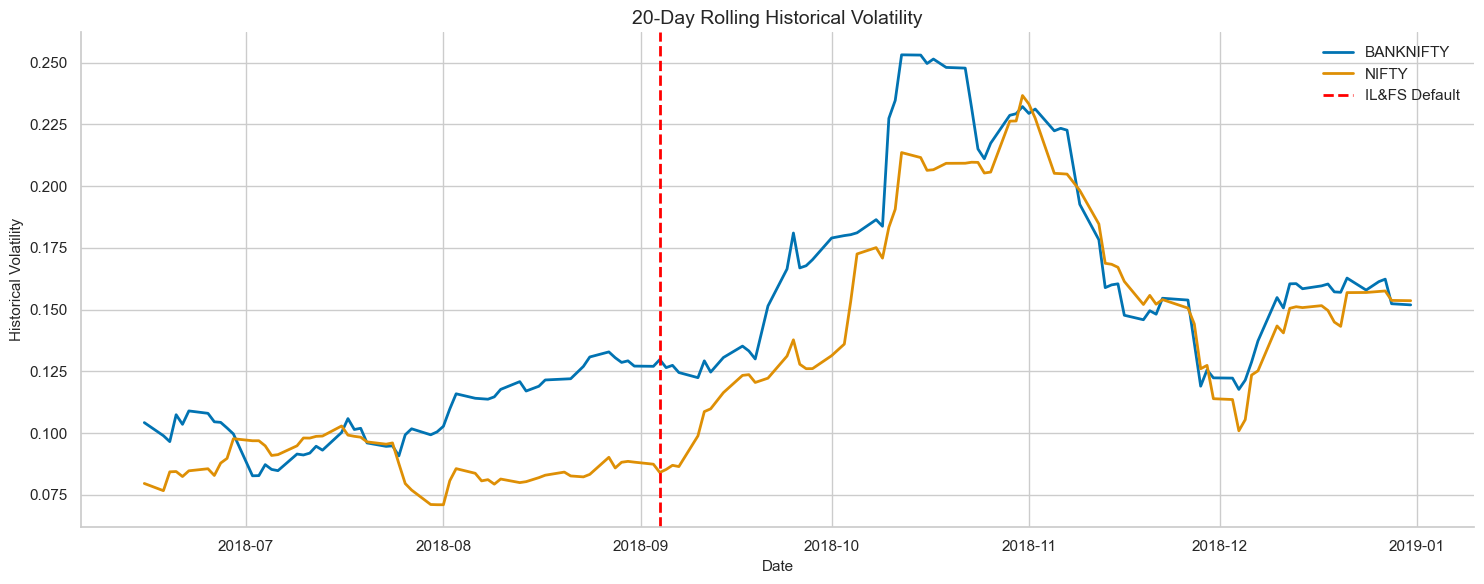


Historical Volatility Before and After IL&FS


,Mean,Median,Std
Period,,,
Post-IL&FS,0.166200,0.157600,0.040700
Pre-IL&FS,0.096900,0.096100,0.014900



✓ historical_volatility Completed Successfully


In [ ]:
# ============================================================
# SECTION 3A: HISTORICAL VOLATILITY ANALYSIS
# ============================================================

print("="*80)
print("HISTORICAL VOLATILITY ANALYSIS")
print("="*80)

import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Prepare Data
# ------------------------------------------------------------

hv = df.copy()

hv["date"] = pd.to_datetime(hv["date"])

hv = hv.dropna(subset=["rolling_20d_volatility"])

# ------------------------------------------------------------
# Convert Event Labels
# ------------------------------------------------------------

hv["Period"] = hv["event_dummy"].map({
    0: "Pre-IL&FS",
    1: "Post-IL&FS"
})

# ------------------------------------------------------------
# Summary Statistics
# ------------------------------------------------------------

hv_summary = (
    hv.groupby(["index","Period"])["rolling_20d_volatility"]
      .agg(
          Mean="mean",
          Median="median",
          Std="std",
          Min="min",
          Max="max"
      )
      .round(4)
)

print("\nHistorical Volatility Summary")
display(hv_summary)

# ------------------------------------------------------------
# Save Table
# ------------------------------------------------------------

hv_summary.to_csv(
    "historical_volatility_summary.csv"
)

# ------------------------------------------------------------
# Daily Average Historical Volatility
# ------------------------------------------------------------

daily_hv = (
    hv.groupby(["date","index"])["rolling_20d_volatility"]
      .mean()
      .reset_index()
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(15,6))

for idx in daily_hv["index"].unique():

    temp = daily_hv[daily_hv["index"]==idx]

    plt.plot(
        temp["date"],
        temp["rolling_20d_volatility"],
        linewidth=2,
        label=idx
    )

plt.axvline(
    pd.Timestamp("2018-09-04"),
    color="red",
    linestyle="--",
    linewidth=2,
    label="IL&FS Default"
)

plt.title("20-Day Rolling Historical Volatility")
plt.xlabel("Date")
plt.ylabel("Historical Volatility")
plt.legend()

plt.tight_layout()

plt.savefig(
    "historical_volatility.png",
    dpi=300
)

plt.show()

# ------------------------------------------------------------
# Pre vs Post Comparison
# ------------------------------------------------------------

comparison = (
    hv.groupby("Period")["rolling_20d_volatility"]
      .agg(
          Mean="mean",
          Median="median",
          Std="std"
      )
      .round(4)
)

print("\nHistorical Volatility Before and After IL&FS")
display(comparison)

comparison.to_csv(
    "historical_volatility_pre_post.csv"
)

print("\n historical_volatility Completed Successfully")

SECTION 3B : HISTORICAL VOLATILITY vs IMPLIED VOLATILITY


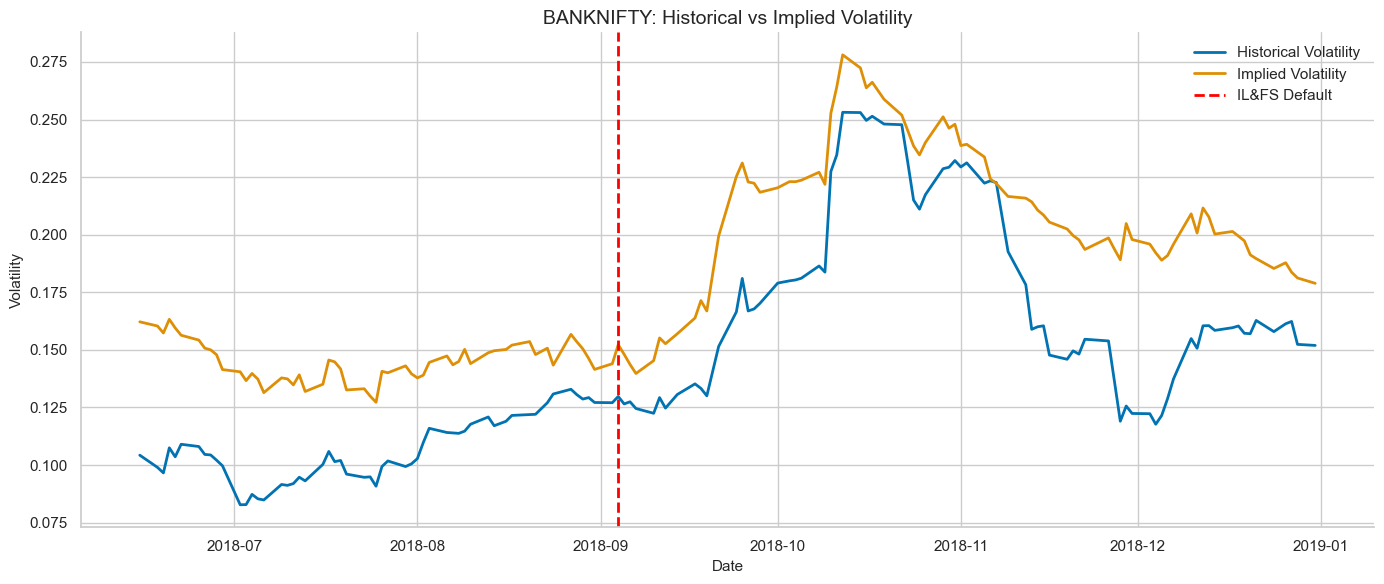

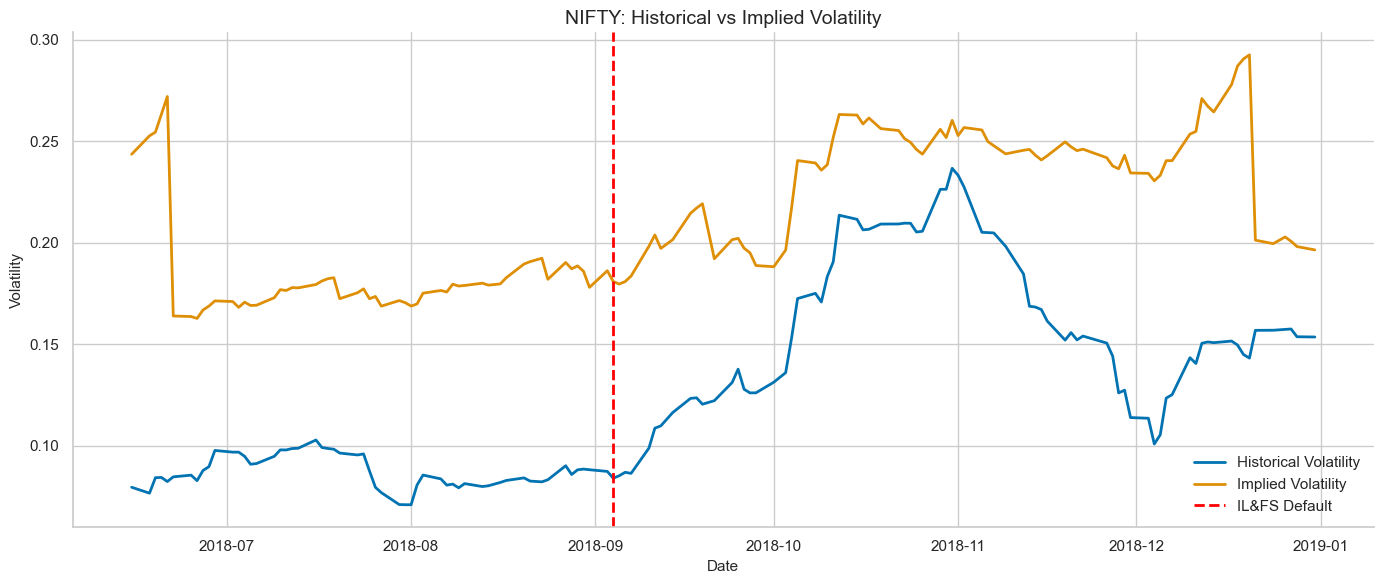


Summary Statistics


Mean_HV  Mean_IV  Mean_Spread  Median_Spread  Std_Spread
index     Period                                                              
BANKNIFTY Post-IL&FS 0.174300 0.210800     0.036500       0.033100    0.031300
          Pre-IL&FS  0.107200 0.145100     0.037800       0.033200    0.026600
NIFTY     Post-IL&FS 0.159100 0.235100     0.075900       0.034900    0.158000
          Pre-IL&FS  0.087300 0.183900     0.096600       0.034100    0.157600


Welch t-test


,Index,t-statistic,p-value
0,BANKNIFTY,-184.850764,0.000000
1,NIFTY,-164.902342,0.000000



Pre vs Post Comparison


,HistoricalVol,ImpliedVol,Spread
Period,,,
Post-IL&FS,0.166800,0.222800,0.056100
Pre-IL&FS,0.097500,0.164000,0.066500


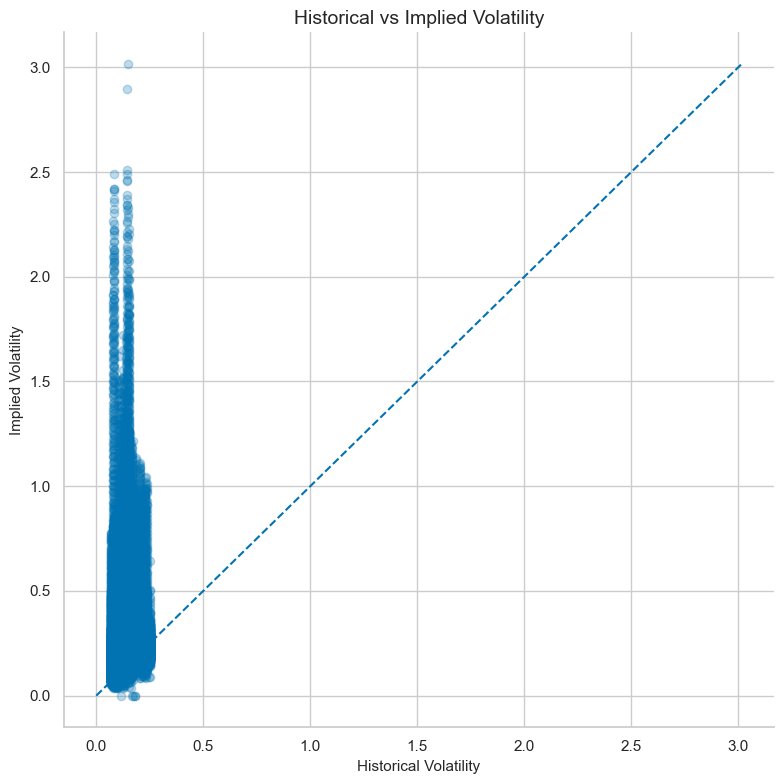


✓ Historical vs Implied Volatility Completed


In [75]:
# ============================================================
# SECTION 3B: HISTORICAL VOLATILITY vs IMPLIED VOLATILITY
# ============================================================

print("="*80)
print("SECTION 3B : HISTORICAL VOLATILITY vs IMPLIED VOLATILITY")
print("="*80)

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import ttest_ind

# ------------------------------------------------------------
# Prepare Data
# ------------------------------------------------------------

vol = df.copy()

vol["date"] = pd.to_datetime(vol["date"])

vol = vol.dropna(
    subset=[
        "rolling_20d_volatility",
        "implied_volatility"
    ]
)

vol["Period"] = vol["event_dummy"].map({
    0: "Pre-IL&FS",
    1: "Post-IL&FS"
})

# ------------------------------------------------------------
# Average Daily HV and IV
# ------------------------------------------------------------

daily_vol = (
    vol.groupby(["date","index"])
       .agg(
            HistoricalVol=("rolling_20d_volatility","mean"),
            ImpliedVol=("implied_volatility","mean")
       )
       .reset_index()
)

# ------------------------------------------------------------
# Plot HV vs IV
# ------------------------------------------------------------

for idx in daily_vol["index"].unique():

    temp = daily_vol[daily_vol["index"]==idx]

    plt.figure(figsize=(14,6))

    plt.plot(
        temp["date"],
        temp["HistoricalVol"],
        linewidth=2,
        label="Historical Volatility"
    )

    plt.plot(
        temp["date"],
        temp["ImpliedVol"],
        linewidth=2,
        label="Implied Volatility"
    )

    plt.axvline(
        pd.Timestamp("2018-09-04"),
        color="red",
        linestyle="--",
        linewidth=2,
        label="IL&FS Default"
    )

    plt.title(f"{idx}: Historical vs Implied Volatility")

    plt.xlabel("Date")
    plt.ylabel("Volatility")

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        f"historical_vs_implied_{idx}.png",
        dpi=300
    )

    plt.show()

# ------------------------------------------------------------
# Volatility Spread
# ------------------------------------------------------------

vol["VolatilitySpread"] = (
    vol["implied_volatility"] -
    vol["rolling_20d_volatility"]
)

# ------------------------------------------------------------
# Summary Statistics
# ------------------------------------------------------------

summary = (
    vol.groupby(["index","Period"])
       .agg(
            Mean_HV=("rolling_20d_volatility","mean"),
            Mean_IV=("implied_volatility","mean"),
            Mean_Spread=("VolatilitySpread","mean"),
            Median_Spread=("VolatilitySpread","median"),
            Std_Spread=("VolatilitySpread","std")
       )
       .round(4)
)

print("\nSummary Statistics")
display(summary)

summary.to_csv(
    "historical_vs_implied_summary.csv"
)

# ------------------------------------------------------------
# Welch t-test (HV vs IV)
# ------------------------------------------------------------

print("\nWelch t-test")

results = []

for idx in vol["index"].unique():

    hv = vol.loc[
        vol["index"]==idx,
        "rolling_20d_volatility"
    ]

    iv = vol.loc[
        vol["index"]==idx,
        "implied_volatility"
    ]

    stat, p = ttest_ind(
        hv,
        iv,
        equal_var=False,
        nan_policy="omit"
    )

    results.append([
        idx,
        stat,
        p
    ])

ttest_table = pd.DataFrame(
    results,
    columns=[
        "Index",
        "t-statistic",
        "p-value"
    ]
)

display(ttest_table)

ttest_table.to_csv(
    "historical_vs_implied_ttest.csv",
    index=False
)

# ------------------------------------------------------------
# Pre vs Post Comparison
# ------------------------------------------------------------

comparison = (
    vol.groupby("Period")
       .agg(
            HistoricalVol=("rolling_20d_volatility","mean"),
            ImpliedVol=("implied_volatility","mean"),
            Spread=("VolatilitySpread","mean")
       )
       .round(4)
)

print("\nPre vs Post Comparison")
display(comparison)

comparison.to_csv(
    "historical_vs_implied_pre_post.csv"
)

# ------------------------------------------------------------
# Scatter Plot
# ------------------------------------------------------------

plt.figure(figsize=(8,8))

plt.scatter(
    vol["rolling_20d_volatility"],
    vol["implied_volatility"],
    alpha=0.25
)

mx = max(
    vol["rolling_20d_volatility"].max(),
    vol["implied_volatility"].max()
)

plt.plot(
    [0,mx],
    [0,mx],
    linestyle="--"
)

plt.xlabel("Historical Volatility")

plt.ylabel("Implied Volatility")

plt.title("Historical vs Implied Volatility")

plt.tight_layout()

plt.savefig(
    "hv_vs_iv_scatter.png",
    dpi=300
)

plt.show()

print("\n✓ Historical vs Implied Volatility Completed")

SECTION 3C : SPOT–FUTURES RELATIONSHIP


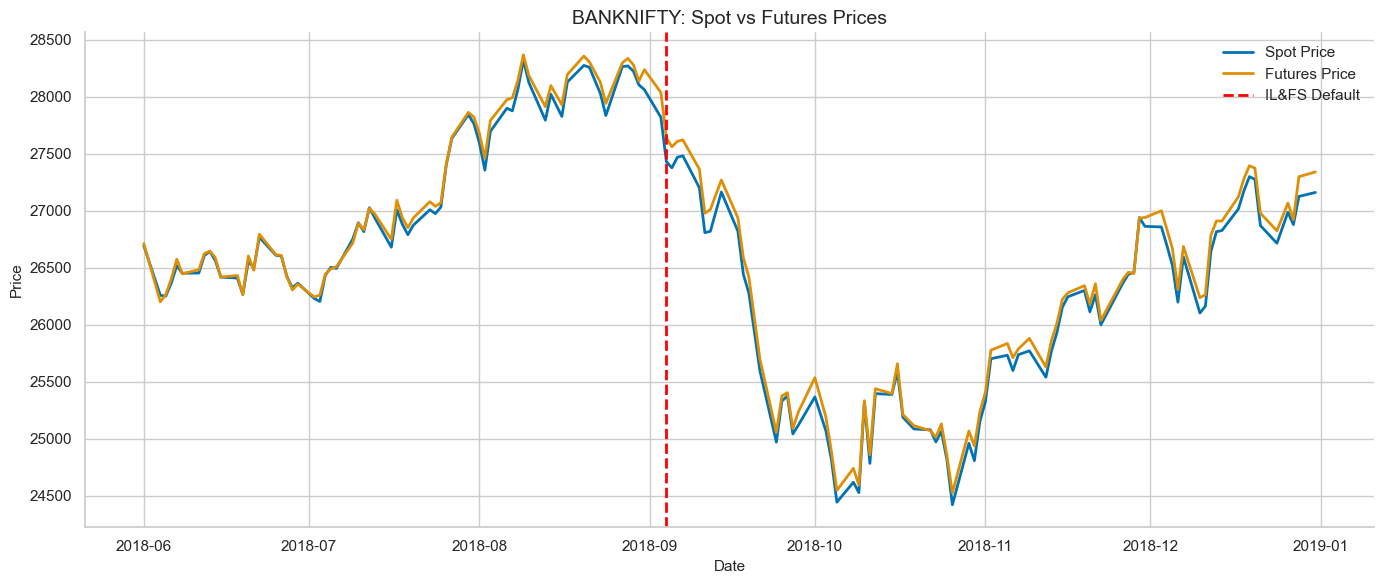

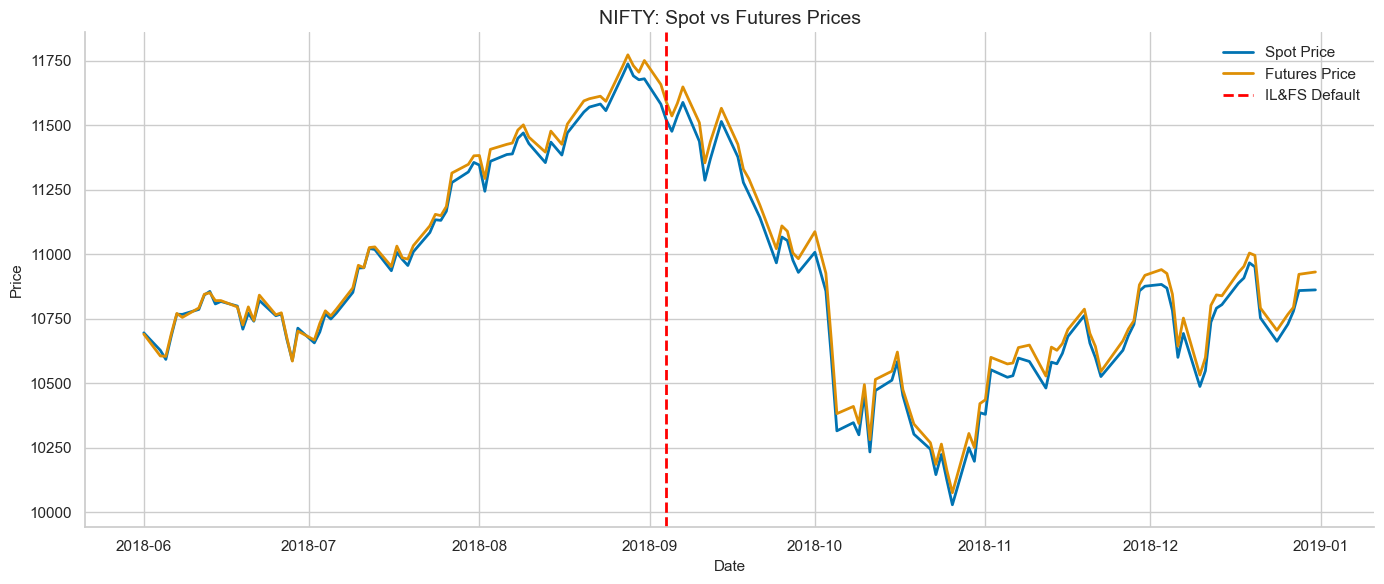

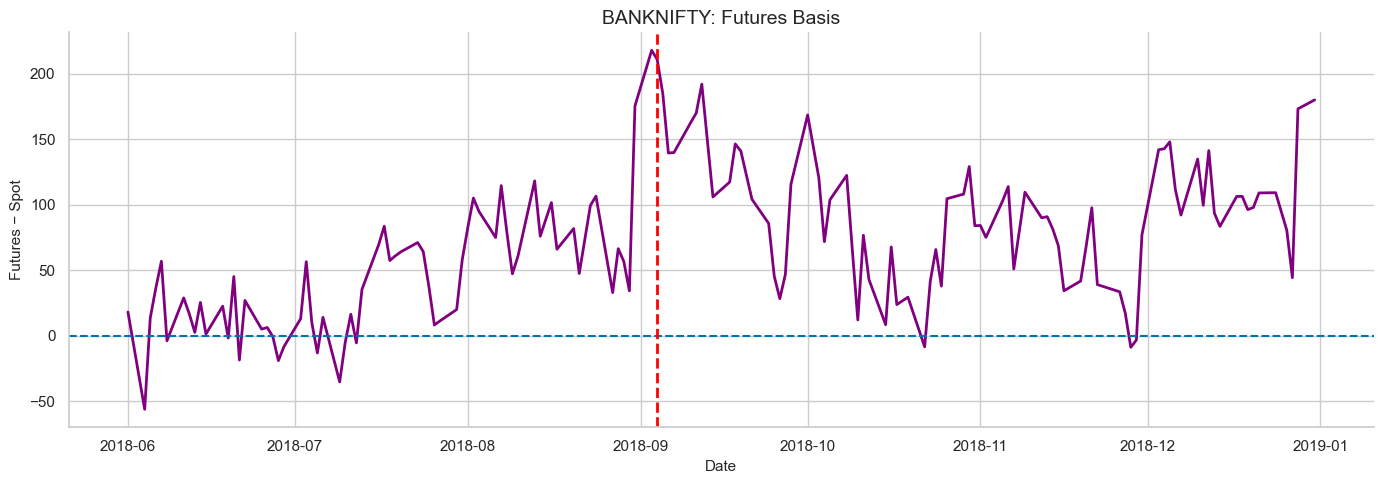

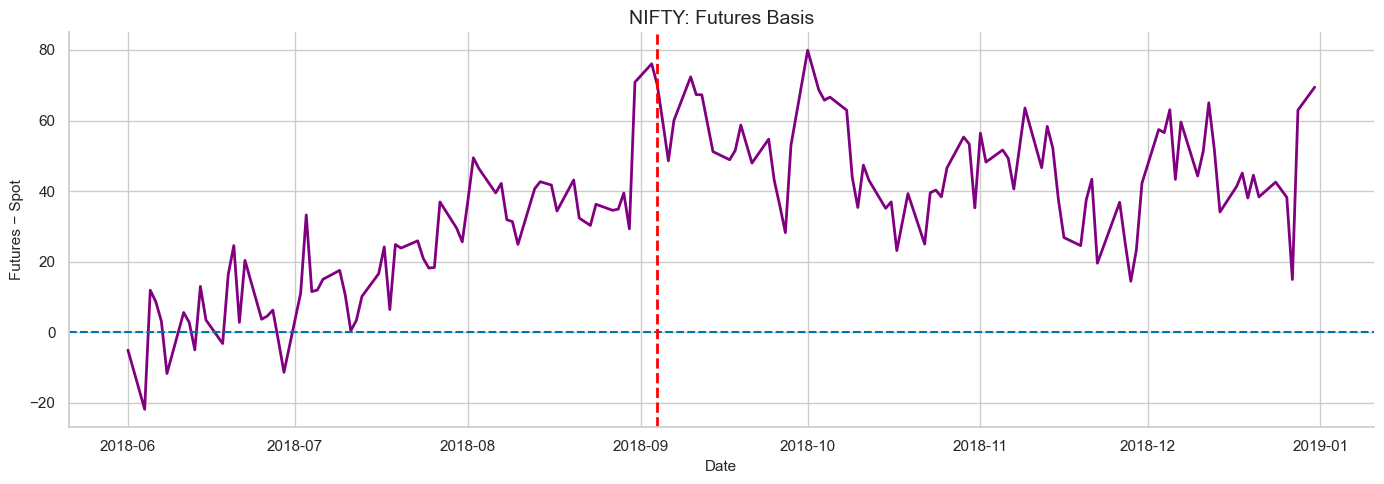


Spot–Futures Summary


MeanSpot    MeanFuture  MeanBasis  MedianBasis  StdBasis
index     Period                                                                  
BANKNIFTY Post-IL&FS 25,970.520000 26,060.210000  89.700000    76.450000 77.450000
          Pre-IL&FS  27,143.290000 27,186.780000  43.490000    31.700000 64.600000
NIFTY     Post-IL&FS 10,727.670000 10,774.770000  47.100000    36.000000 35.850000
          Pre-IL&FS  11,084.260000 11,105.200000  20.940000    16.200000 25.670000


Spot–Futures Correlation


,Index,Correlation,P-value
0,BANKNIFTY,0.997134,0.000000
1,NIFTY,0.996304,0.000000



Basis Before and After IL&FS


,MeanBasis,MeanRelativeBasis
Period,,
Post-IL&FS,68.012400,0.391700
Pre-IL&FS,31.946200,0.171500



 Spot–Futures Relationship Completed


In [76]:
# ============================================================
# SECTION 3C: SPOT–FUTURES RELATIONSHIP
# ============================================================

print("="*80)
print("SECTION 3C : SPOT–FUTURES RELATIONSHIP")
print("="*80)

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr

# ------------------------------------------------------------
# Prepare Data
# ------------------------------------------------------------

sf = df.copy()

sf["date"] = pd.to_datetime(sf["date"])

sf = sf.dropna(subset=["spot_price","future_price"])

sf["Period"] = sf["event_dummy"].map({
    0:"Pre-IL&FS",
    1:"Post-IL&FS"
})

# ------------------------------------------------------------
# Basis
# ------------------------------------------------------------

sf["Basis"] = sf["future_price"] - sf["spot_price"]

sf["RelativeBasis"] = (
    sf["Basis"] /
    sf["spot_price"]
) * 100

# ------------------------------------------------------------
# Daily Average
# ------------------------------------------------------------

daily = (
    sf.groupby(["date","index"])
      .agg(
          Spot=("spot_price","mean"),
          Futures=("future_price","mean"),
          Basis=("Basis","mean"),
          RelativeBasis=("RelativeBasis","mean")
      )
      .reset_index()
)

# ------------------------------------------------------------
# Spot vs Futures Plot
# ------------------------------------------------------------

for idx in daily["index"].unique():

    temp = daily[daily["index"]==idx]

    plt.figure(figsize=(14,6))

    plt.plot(
        temp["date"],
        temp["Spot"],
        linewidth=2,
        label="Spot Price"
    )

    plt.plot(
        temp["date"],
        temp["Futures"],
        linewidth=2,
        label="Futures Price"
    )

    plt.axvline(
        pd.Timestamp("2018-09-04"),
        color="red",
        linestyle="--",
        linewidth=2,
        label="IL&FS Default"
    )

    plt.title(f"{idx}: Spot vs Futures Prices")

    plt.xlabel("Date")

    plt.ylabel("Price")

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        f"spot_vs_futures_{idx}.png",
        dpi=300
    )

    plt.show()

# ------------------------------------------------------------
# Basis Plot
# ------------------------------------------------------------

for idx in daily["index"].unique():

    temp = daily[daily["index"]==idx]

    plt.figure(figsize=(14,5))

    plt.plot(
        temp["date"],
        temp["Basis"],
        linewidth=2,
        color="purple"
    )

    plt.axhline(
        0,
        linestyle="--"
    )

    plt.axvline(
        pd.Timestamp("2018-09-04"),
        color="red",
        linestyle="--",
        linewidth=2
    )

    plt.title(f"{idx}: Futures Basis")

    plt.xlabel("Date")

    plt.ylabel("Futures − Spot")

    plt.tight_layout()

    plt.savefig(
        f"basis_{idx}.png",
        dpi=300
    )

    plt.show()

# ------------------------------------------------------------
# Summary Statistics
# ------------------------------------------------------------

summary = (
    sf.groupby(["index","Period"])
      .agg(
          MeanSpot=("spot_price","mean"),
          MeanFuture=("future_price","mean"),
          MeanBasis=("Basis","mean"),
          MedianBasis=("Basis","median"),
          StdBasis=("Basis","std")
      )
      .round(2)
)

print("\nSpot–Futures Summary")
display(summary)

summary.to_csv(
    "spot_futures_summary.csv"
)

# ------------------------------------------------------------
# Correlation
# ------------------------------------------------------------

results = []

for idx in sf["index"].unique():

    temp = sf[sf["index"]==idx]

    corr, p = pearsonr(
        temp["spot_price"],
        temp["future_price"]
    )

    results.append([
        idx,
        corr,
        p
    ])

corr_table = pd.DataFrame(
    results,
    columns=[
        "Index",
        "Correlation",
        "P-value"
    ]
)

print("\nSpot–Futures Correlation")
display(corr_table)

corr_table.to_csv(
    "spot_futures_correlation.csv",
    index=False
)

# ------------------------------------------------------------
# Pre vs Post Basis
# ------------------------------------------------------------

comparison = (
    sf.groupby("Period")
      .agg(
          MeanBasis=("Basis","mean"),
          MeanRelativeBasis=("RelativeBasis","mean")
      )
      .round(4)
)

print("\nBasis Before and After IL&FS")
display(comparison)

comparison.to_csv(
    "basis_pre_post.csv"
)

print("\n Spot–Futures Relationship Completed")

SECTION 3D : PUT-CALL PARITY ANALYSIS
Matched Call-Put Pairs: 117,138

Put-Call Parity Summary


MeanDeviation  MedianDeviation  MeanAbsDeviation  StdDeviation
index     Period                                                                    
BANKNIFTY Post-IL&FS       7.724500        13.407800         24.458700     45.349100
          Pre-IL&FS        7.645700        17.638100         28.461700     43.585000
NIFTY     Post-IL&FS      10.799500        14.715400         30.176500     40.781300
          Pre-IL&FS        8.426900        17.406000         43.847800     57.812400

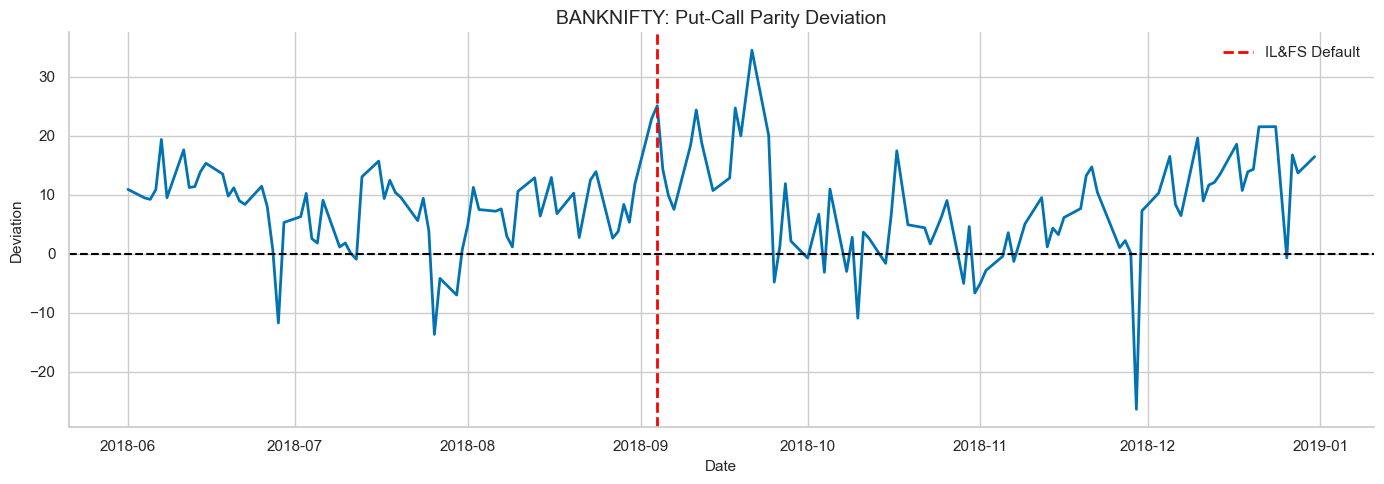

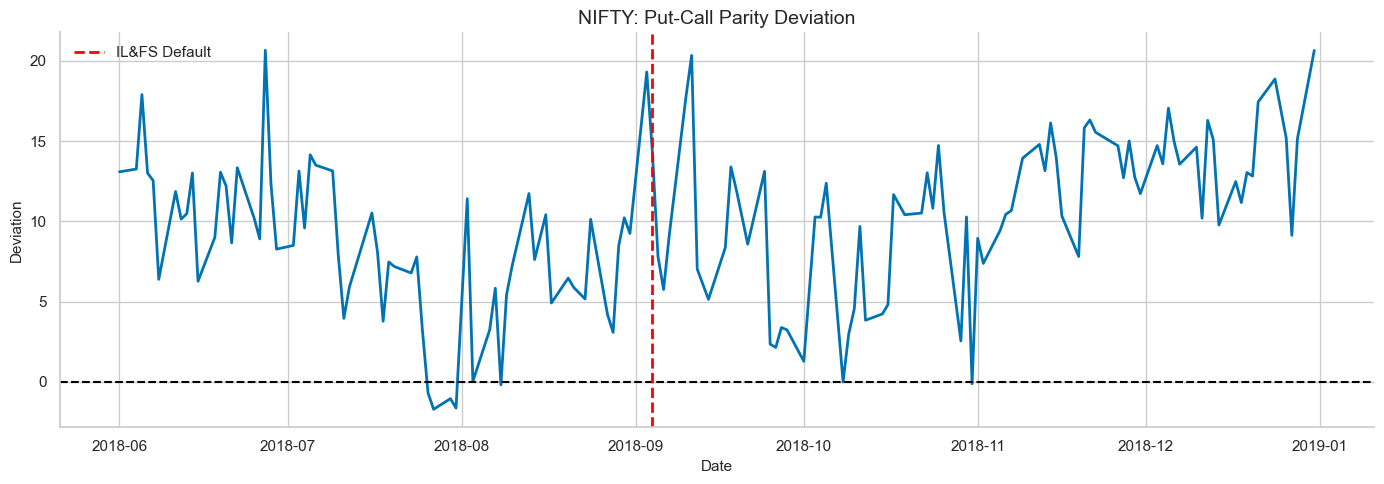


Welch t-test
---------------------------
T-statistic : 39.7027
P-value     : 0.000000

Pre vs Post Comparison


,MeanDeviation,MeanAbsoluteDeviation
Period,,
Post-IL&FS,9.236800,27.270600
Pre-IL&FS,8.016900,35.772700



✓ Put-Call Parity Analysis Completed


In [78]:
# ============================================================
# SECTION 3D: PUT-CALL PARITY ANALYSIS
# ============================================================

print("="*80)
print("SECTION 3D : PUT-CALL PARITY ANALYSIS")
print("="*80)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind

# ------------------------------------------------------------
# Split Calls and Puts
# ------------------------------------------------------------

calls = df[df["option_type"].str.upper().isin(["CE","CALL"])].copy()

puts = df[df["option_type"].str.upper().isin(["PE","PUT"])].copy()

# ------------------------------------------------------------
# Merge Matching Contracts
# ------------------------------------------------------------

merge_cols = [
    "date",
    "index",
    "expiry",
    "strike"
]

parity = pd.merge(
    calls,
    puts,
    on=merge_cols,
    suffixes=("_call","_put")
)

print(f"Matched Call-Put Pairs: {len(parity):,}")

# ------------------------------------------------------------
# Put-Call Parity
# ------------------------------------------------------------

parity["PresentValueStrike"] = (
    parity["strike"] *
    np.exp(
        -parity["risk_free_rate_call"] *
        parity["time_to_expiry_years_call"]
    )
)

parity["Parity_LHS"] = (
    parity["option_price_call"] -
    parity["option_price_put"]
)

parity["Parity_RHS"] = (
    parity["spot_price_call"] -
    parity["PresentValueStrike"]
)

parity["Parity_Deviation"] = (
    parity["Parity_LHS"] -
    parity["Parity_RHS"]
)

parity["AbsoluteDeviation"] = (
    parity["Parity_Deviation"].abs()
)

# ------------------------------------------------------------
# Event Labels
# ------------------------------------------------------------

parity["Period"] = parity["event_dummy_call"].map({
    0:"Pre-IL&FS",
    1:"Post-IL&FS"
})

# ------------------------------------------------------------
# Summary Statistics
# ------------------------------------------------------------

summary = (
    parity.groupby(["index","Period"])
          .agg(
              MeanDeviation=("Parity_Deviation","mean"),
              MedianDeviation=("Parity_Deviation","median"),
              MeanAbsDeviation=("AbsoluteDeviation","mean"),
              StdDeviation=("Parity_Deviation","std")
          )
          .round(4)
)

print("\nPut-Call Parity Summary")
display(summary)

summary.to_csv(
    "put_call_parity_summary.csv"
)

# ------------------------------------------------------------
# Daily Average Deviation
# ------------------------------------------------------------

daily = (
    parity.groupby(["date","index"])
          .agg(
              MeanDeviation=("Parity_Deviation","mean")
          )
          .reset_index()
)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

for idx in daily["index"].unique():

    temp = daily[daily["index"]==idx]

    plt.figure(figsize=(14,5))

    plt.plot(
        temp["date"],
        temp["MeanDeviation"],
        linewidth=2
    )

    plt.axhline(
        0,
        linestyle="--",
        color="black"
    )

    plt.axvline(
        pd.Timestamp("2018-09-04"),
        color="red",
        linestyle="--",
        linewidth=2,
        label="IL&FS Default"
    )

    plt.title(f"{idx}: Put-Call Parity Deviation")

    plt.xlabel("Date")

    plt.ylabel("Deviation")

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        f"put_call_parity_{idx}.png",
        dpi=300
    )

    plt.show()

# ------------------------------------------------------------
# Statistical Test
# ------------------------------------------------------------

pre = parity.loc[
    parity["Period"]=="Pre-IL&FS",
    "AbsoluteDeviation"
]

post = parity.loc[
    parity["Period"]=="Post-IL&FS",
    "AbsoluteDeviation"
]

t,p = ttest_ind(
    pre,
    post,
    equal_var=False,
    nan_policy="omit"
)

print("\nWelch t-test")
print("---------------------------")
print(f"T-statistic : {t:.4f}")
print(f"P-value     : {p:.6f}")

# ------------------------------------------------------------
# Pre/Post Comparison
# ------------------------------------------------------------

comparison = (
    parity.groupby("Period")
          .agg(
              MeanDeviation=("Parity_Deviation","mean"),
              MeanAbsoluteDeviation=("AbsoluteDeviation","mean")
          )
          .round(4)
)

print("\nPre vs Post Comparison")
display(comparison)

comparison.to_csv(
    "put_call_pre_post.csv"
)

print("\n✓ Put-Call Parity Analysis Completed")

In [72]:
for col in df.columns:
    print(col)

date
index
expiry
strike
option_type
spot_price
future_price
option_price
option_open
option_high
option_low
option_close
option_settlement_price
volume
turnover
open_interest
change_in_oi
india_vix
risk_free_rate
risk_free_rate_percent
days_to_expiry
time_to_expiry_days
trading_days_to_expiry
time_to_expiry_years
event_date
event_dummy
days_from_event
weeks_from_event
pre_post_period
moneyness
daily_return_spot
log_return_spot
rolling_20d_volatility
year
month
week
day_of_week
is_month_end
spot_open
spot_high
spot_low
shares_traded
spot_turnover_inr_cr
future_expiry
future_match_type
future_open
future_high
future_low
future_close
future_settlement_price
future_days_to_expiry
instrument
india_vix_open
india_vix_high
india_vix_low
india_vix_adj_close
log_moneyness
sigma
d1
d2
bs_price
moneyness_band
implied_volatility
iv_converged
d1_iv
d2_iv
delta
gamma
theta
vega
rho
next_date
next_option_price
next_spot_price
next_delta
hedge_interval_valid
daily_hedge_ratio
option_pnl
spot_pnl
cash

## SECTION 4 - Greeks

The Greeks are computed using implied volatility rather than India VIX. This is
the appropriate input for hedging because the hedge ratio should reflect the
option's own market-implied volatility, not a broad market volatility index.
Rows with missing implied volatility produce missing Greeks so that numerical
failures remain visible in the audit trail.

Conventions used below:

- `delta`: unit change in option value per unit change in spot.
- `gamma`: second derivative of option value with respect to spot.
- `theta`: calendar-day theta, obtained by dividing annual theta by 365.
- `vega`: option value change for a one percentage point volatility change.
- `rho`: option value change for a one percentage point interest-rate change.

The sign of delta follows the standard long-option convention: calls have
positive delta and puts have negative delta. The hedge in Section 5 takes the
opposite position in the underlying index.


In [12]:
# ---------------------------------------------------------------
# Vectorised Greek calculations
# ---------------------------------------------------------------
# d1_iv and d2_iv are retained to make clear that Greeks use implied
# volatility, not India VIX.

def black_scholes_greeks_vectorised(
    spot: pd.Series | np.ndarray,
    strike: pd.Series | np.ndarray,
    rate: pd.Series | np.ndarray,
    time_to_expiry: pd.Series | np.ndarray,
    implied_volatility: pd.Series | np.ndarray,
    option_type: pd.Series | np.ndarray,
) -> pd.DataFrame:
    '''Compute Black-Scholes Greeks with implied volatility.'''

    spot_arr = np.asarray(spot, dtype=float)
    strike_arr = np.asarray(strike, dtype=float)
    rate_arr = np.asarray(rate, dtype=float)
    time_arr = np.asarray(time_to_expiry, dtype=float)
    vol_arr = np.asarray(implied_volatility, dtype=float)
    option_labels = normalise_option_type(option_type)

    n_obs = len(spot_arr)
    d1_iv = np.full(n_obs, np.nan, dtype=float)
    d2_iv = np.full(n_obs, np.nan, dtype=float)
    delta = np.full(n_obs, np.nan, dtype=float)
    gamma = np.full(n_obs, np.nan, dtype=float)
    theta = np.full(n_obs, np.nan, dtype=float)
    vega = np.full(n_obs, np.nan, dtype=float)
    rho = np.full(n_obs, np.nan, dtype=float)

    call_mask = option_labels.isin(["CE", "C", "CALL"]).to_numpy()
    put_mask = option_labels.isin(["PE", "P", "PUT"]).to_numpy()
    recognised_type = call_mask | put_mask

    valid = (
        np.isfinite(spot_arr)
        & np.isfinite(strike_arr)
        & np.isfinite(rate_arr)
        & np.isfinite(time_arr)
        & np.isfinite(vol_arr)
        & (spot_arr > 0)
        & (strike_arr > 0)
        & (time_arr > 0)
        & (vol_arr > 0)
        & recognised_type
    )

    if valid.any():
        sqrt_time = np.sqrt(time_arr[valid])
        discount_factor = np.exp(-rate_arr[valid] * time_arr[valid])
        log_moneyness = np.log(spot_arr[valid] / strike_arr[valid])

        d1_valid = (
            log_moneyness
            + (rate_arr[valid] + 0.5 * vol_arr[valid] ** 2) * time_arr[valid]
        ) / (vol_arr[valid] * sqrt_time)
        d2_valid = d1_valid - vol_arr[valid] * sqrt_time
        pdf_d1 = norm.pdf(d1_valid)

        valid_positions = np.where(valid)[0]
        call_positions = call_mask[valid_positions]
        put_positions = put_mask[valid_positions]

        d1_iv[valid_positions] = d1_valid
        d2_iv[valid_positions] = d2_valid

        delta_valid = np.full(len(valid_positions), np.nan, dtype=float)
        delta_valid[call_positions] = norm.cdf(d1_valid[call_positions])
        delta_valid[put_positions] = norm.cdf(d1_valid[put_positions]) - 1.0

        gamma_valid = pdf_d1 / (spot_arr[valid] * vol_arr[valid] * sqrt_time)

        common_theta = -(
            spot_arr[valid] * pdf_d1 * vol_arr[valid]
        ) / (2.0 * sqrt_time)
        theta_annual = np.full(len(valid_positions), np.nan, dtype=float)
        theta_annual[call_positions] = (
            common_theta[call_positions]
            - rate_arr[valid][call_positions]
            * strike_arr[valid][call_positions]
            * discount_factor[call_positions]
            * norm.cdf(d2_valid[call_positions])
        )
        theta_annual[put_positions] = (
            common_theta[put_positions]
            + rate_arr[valid][put_positions]
            * strike_arr[valid][put_positions]
            * discount_factor[put_positions]
            * norm.cdf(-d2_valid[put_positions])
        )

        vega_valid = spot_arr[valid] * pdf_d1 * sqrt_time / 100.0

        rho_valid = np.full(len(valid_positions), np.nan, dtype=float)
        rho_valid[call_positions] = (
            strike_arr[valid][call_positions]
            * time_arr[valid][call_positions]
            * discount_factor[call_positions]
            * norm.cdf(d2_valid[call_positions])
            / 100.0
        )
        rho_valid[put_positions] = (
            -strike_arr[valid][put_positions]
            * time_arr[valid][put_positions]
            * discount_factor[put_positions]
            * norm.cdf(-d2_valid[put_positions])
            / 100.0
        )

        delta[valid_positions] = delta_valid
        gamma[valid_positions] = gamma_valid
        theta[valid_positions] = theta_annual / RISK_FREE_DAYS_PER_YEAR
        vega[valid_positions] = vega_valid
        rho[valid_positions] = rho_valid

    return pd.DataFrame(
        {
            "d1_iv": d1_iv,
            "d2_iv": d2_iv,
            "delta": delta,
            "gamma": gamma,
            "theta": theta,
            "vega": vega,
            "rho": rho,
        },
        index=getattr(spot, "index", None),
    )


greek_results = black_scholes_greeks_vectorised(
    spot=df["spot_price"],
    strike=df["strike"],
    rate=df["risk_free_rate"],
    time_to_expiry=df["time_to_expiry_years"],
    implied_volatility=df["implied_volatility"],
    option_type=df["option_type"],
)

df[["d1_iv", "d2_iv", "delta", "gamma", "theta", "vega", "rho"]] = greek_results
display(df[["option_type", "implied_volatility", "delta", "gamma", "theta", "vega", "rho"]].head())


,option_type,implied_volatility,delta,gamma,theta,vega,rho
0,CE,0.290189,0.995738,0.000009,-4.820150,0.631677,8.202620
1,PE,0.213427,-0.000186,0.000001,-0.028346,0.035621,-0.001783
2,CE,0.282577,0.995595,0.000009,-4.839360,0.650597,8.236787
3,PE,0.207376,-0.000191,0.000001,-0.028229,0.036546,-0.001832
4,CE,0.274965,0.995444,0.000010,-4.858373,0.670411,8.270883


In [13]:
# ---------------------------------------------------------------
# Greek summary diagnostics
# ---------------------------------------------------------------
# These distributions are useful both as numerical checks and as
# dissertation evidence on risk exposures before and after IL&FS.

GREEK_COLUMNS = ["delta", "gamma", "theta", "vega", "rho"]


def greek_summary_table(data: pd.DataFrame, group_columns: list[str]) -> pd.DataFrame:
    '''Return grouped Greek diagnostics with flattened column names.'''

    table = data.groupby(group_columns, observed=True)[GREEK_COLUMNS].agg(
        ["count", "mean", "std", "median", "min", "max"]
    )
    table.columns = ["_".join(column).strip() for column in table.columns]
    return table.reset_index()


greek_summary_overall = greek_summary_table(df.assign(sample="Overall"), ["sample"])
greek_summary_by_pre_post = greek_summary_table(df, ["pre_post_period"])


greek_missing = df[GREEK_COLUMNS].isna().mean().rename("missing_share").reset_index()
greek_missing = greek_missing.rename(columns={"index": "greek"})

display(greek_summary_overall)
display(greek_summary_by_pre_post)
display(greek_missing)


,sample,delta_count,delta_mean,delta_std,delta_median,delta_min,delta_max,gamma_count,gamma_mean,gamma_std,gamma_median,gamma_min,gamma_max,theta_count,theta_mean,theta_std,theta_median,theta_min,theta_max,vega_count,vega_mean,vega_std,vega_median,vega_min,vega_max,rho_count,rho_mean,rho_std,rho_median,rho_min,rho_max
0,Overall,233004,0.128082,0.596732,0.021575,-1.000000,0.999852,233004,0.000200,0.000194,0.000163,0.000000,0.002766,233004,-3.440204,3.906501,-2.156781,-67.669442,5.808889,233004,16.746053,13.315167,14.395822,0.000000,55.590349,233004,2.706859,22.785452,0.261507,-123.991829,87.530043


,index,option_type,moneyness_band,pre_post_period,delta_count,delta_mean,delta_std,delta_median,delta_min,delta_max,gamma_count,gamma_mean,gamma_std,gamma_median,gamma_min,gamma_max,theta_count,theta_mean,theta_std,theta_median,theta_min,theta_max,vega_count,vega_mean,vega_std,vega_median,vega_min,vega_max,rho_count,rho_mean,rho_std,rho_median,rho_min,rho_max
0,BANKNIFTY,CE,ATM,Post,10914,0.546040,0.132307,0.554449,0.048909,0.989390,10914,0.000258,0.000109,0.000228,0.000092,0.001219,10914,-11.710502,3.017292,-11.075495,-47.321899,-3.353378,10914,30.900372,9.872168,31.835121,1.016479,53.734930,10914,14.514708,8.332535,13.782301,0.251018,44.570405
1,BANKNIFTY,CE,ATM,Pre,9431,0.550342,0.170904,0.561419,0.038271,0.996393,9431,0.000327,0.000131,0.000292,0.000047,0.001139,9431,-9.043218,1.981196,-8.654937,-19.625249,-2.688851,9431,30.945137,10.613138,32.072425,0.445334,55.589807,9431,15.494667,9.215931,14.590468,0.193287,47.458407
2,BANKNIFTY,CE,ITM,Post,11283,0.868984,0.087525,0.872908,0.656395,0.999646,11283,0.000110,0.000057,0.000113,0.000001,0.000306,11283,-8.797259,2.571937,-8.630544,-61.862339,-4.273768,11283,16.765467,11.137134,16.201802,0.106775,46.226297,11283,19.884752,9.930762,19.076838,3.088916,49.524172
3,BANKNIFTY,CE,ITM,Pre,9709,0.916486,0.068930,0.932187,0.695922,0.999715,9709,0.000100,0.000063,0.000096,0.000001,0.000282,9709,-6.848075,1.470568,-6.629761,-32.796172,-4.226844,9709,12.631711,10.281112,10.453571,0.046509,46.365773,9709,21.119365,10.851845,20.202787,3.710010,54.332182
4,BANKNIFTY,CE,OTM,Post,12503,0.167019,0.130926,0.147416,0.000155,0.484546,12503,0.000130,0.000074,0.000141,0.000000,0.000339,12503,-5.887435,3.539650,-6.153304,-19.541638,-0.017985,12503,18.300191,13.736879,16.784702,0.025403,53.352259,12503,5.093245,5.584378,3.021283,0.000968,28.549041
5,BANKNIFTY,CE,OTM,Pre,6158,0.175422,0.109381,0.173790,0.000305,0.456695,6158,0.000182,0.000068,0.000191,0.000002,0.000358,6158,-4.799019,2.075676,-5.075408,-12.151360,-0.037397,6158,21.666136,13.503869,21.781728,0.043530,54.003927,6158,6.024677,5.620618,4.564929,0.001635,27.911927
6,BANKNIFTY,PE,ATM,Post,10898,-0.451117,0.129337,-0.443795,-0.980086,-0.078618,10898,0.000258,0.000107,0.000230,0.000114,0.001077,10898,-6.907185,3.310522,-6.200393,-31.146094,4.501946,10898,30.935896,9.761939,31.808229,1.876692,53.733262,10898,-13.029243,7.321346,-12.272749,-38.628170,-0.415255
7,BANKNIFTY,PE,ATM,Pre,9495,-0.445837,0.166864,-0.436384,-0.973181,-0.062597,9495,0.000323,0.000115,0.000296,0.000139,0.001233,9495,-4.346506,2.278606,-3.818643,-22.041859,4.497578,9495,30.905983,10.416362,31.844174,2.737231,55.590349,9495,-12.992457,7.697708,-11.958847,-41.185340,-0.333520
8,BANKNIFTY,PE,ITM,Post,11371,-0.819821,0.127222,-0.828250,-1.000000,-0.517470,11371,0.000139,0.000071,0.000150,0.000000,0.000338,11371,-1.144006,3.902681,-1.504457,-67.669442,5.808889,11371,19.651563,13.327057,18.805137,0.000000,53.268497,11371,-21.974144,10.200759,-21.336514,-57.998437,-3.820740
9,BANKNIFTY,PE,ITM,Pre,5753,-0.820662,0.102197,-0.823045,-0.999942,-0.549351,5753,0.000193,0.000064,0.000201,0.000001,0.000331,5753,0.261020,2.126142,0.128990,-19.345801,5.538840,5753,22.382175,12.710247,22.244596,0.012021,54.418468,5753,-24.449475,10.477069,-24.427487,-55.832526,-4.427907


,greek,missing_share
0,delta,0.061327
1,gamma,0.061327
2,theta,0.061327
3,vega,0.061327
4,rho,0.061327


## SECTION 5 - Delta Hedging

This section constructs a one-period daily delta hedge for each option contract.
The hedge is initiated at date `t` using the implied-volatility delta available
at date `t`, and the next observation for the same index-expiry-strike-option
contract is used to evaluate the hedge over `(t, t+1]`. The hedge ratio is
therefore `delta_t`, not a look-ahead `delta_{t+1}`.

The maintained position is a long option hedged by short `delta_t` units of the
underlying index. The initial cash account is the proceeds from the short index
position less the option purchase:

`cash_t = delta_t * spot_t - option_price_t`

The cash account accrues at the observed risk-free rate over the actual calendar
gap between observations. The one-period hedged P&L is:

`hedged_pnl = option_pnl - delta_t * spot_pnl + cash_pnl`

This is a discrete daily hedge, not a continuous-time replication strategy.
Rebalancing is recorded at the next observation through the cash-flow required
to move from `delta_t` to `delta_{t+1}`, but the reported hedging error is the
economically standard one-period replication error before the next rebalance.

Implementation assumptions required by the data are explicit: intervals with
missing next-day prices, missing deltas, non-positive prices, non-positive spot,
non-positive time gaps, or next observations after expiry are excluded from
hedge-error statistics; no interpolation is performed; transaction costs,
bid-ask spreads, margin, taxes, and market impact are assumed to be zero.


In [14]:
# ---------------------------------------------------------------
# Hedging helper functions
# ---------------------------------------------------------------
# The contract key keeps each option series separate across index,
# expiry, strike, and option type.

CONTRACT_COLUMNS = ["index", "expiry", "strike", "option_type"]


def safe_divide(numerator: pd.Series | np.ndarray, denominator: pd.Series | np.ndarray) -> np.ndarray:
    '''Divide while returning NaN where the denominator is zero or missing.'''

    numerator_arr = np.asarray(numerator, dtype=float)
    denominator_arr = np.asarray(denominator, dtype=float)
    result = np.full(len(numerator_arr), np.nan, dtype=float)
    valid = np.isfinite(numerator_arr) & np.isfinite(denominator_arr) & (denominator_arr != 0)
    result[valid] = numerator_arr[valid] / denominator_arr[valid]
    return result


def construct_daily_delta_hedge(data: pd.DataFrame) -> pd.DataFrame:
    '''Return one-period daily hedging metrics aligned to the original index.'''

    hedge_source = (
        data.reset_index(names="row_id")
        .sort_values(CONTRACT_COLUMNS + ["date"], kind="mergesort")
        .copy()
    )

    grouped_contracts = hedge_source.groupby(CONTRACT_COLUMNS, observed=True, sort=False)

    hedge_source["next_date"] = grouped_contracts["date"].shift(-1)
    hedge_source["next_option_price"] = grouped_contracts["option_price"].shift(-1)
    hedge_source["next_spot_price"] = grouped_contracts["spot_price"].shift(-1)
    hedge_source["next_delta"] = grouped_contracts["delta"].shift(-1)

    hedge_source["hedge_dt_years"] = (
        (hedge_source["next_date"] - hedge_source["date"]).dt.days / RISK_FREE_DAYS_PER_YEAR
    )

    finite_hedge_inputs = hedge_source[
        [
            "option_price",
            "spot_price",
            "next_option_price",
            "next_spot_price",
            "delta",
            "risk_free_rate",
            "hedge_dt_years",
        ]
    ].replace([np.inf, -np.inf], np.nan).notna().all(axis=1)

    hedge_source["hedge_interval_valid"] = (
        finite_hedge_inputs
        & hedge_source["next_date"].notna()
        & hedge_source["expiry"].notna()
        & hedge_source["next_date"].le(hedge_source["expiry"])
        & hedge_source["next_date"].gt(hedge_source["date"])
        & hedge_source["hedge_dt_years"].gt(0)
        & hedge_source["option_price"].gt(0)
        & hedge_source["next_option_price"].gt(0)
        & hedge_source["spot_price"].gt(0)
        & hedge_source["next_spot_price"].gt(0)
    )

    hedge_source["daily_hedge_ratio"] = hedge_source["delta"]
    hedge_source["option_pnl"] = hedge_source["next_option_price"] - hedge_source["option_price"]
    hedge_source["spot_pnl"] = hedge_source["next_spot_price"] - hedge_source["spot_price"]

    # A zero-cost long-option hedged portfolio has a cash balance equal
    # to proceeds from the short stock hedge minus the option purchase.
    hedge_source["cash_account_start"] = (
        hedge_source["daily_hedge_ratio"] * hedge_source["spot_price"]
        - hedge_source["option_price"]
    )
    hedge_source["cash_balance"] = hedge_source["cash_account_start"]
    hedge_source["cash_account"] = hedge_source["cash_account_start"]
    hedge_source["cash_pnl"] = hedge_source["cash_account_start"] * (
        np.exp(hedge_source["risk_free_rate"] * hedge_source["hedge_dt_years"]) - 1.0
    )
    hedge_source["cash_account_end_before_rebalance"] = (
        hedge_source["cash_account_start"] + hedge_source["cash_pnl"]
    )

    hedge_source["stock_hedge_pnl"] = -hedge_source["daily_hedge_ratio"] * hedge_source["spot_pnl"]
    hedge_source["hedged_portfolio_value_next"] = (
        hedge_source["next_option_price"]
        - hedge_source["daily_hedge_ratio"] * hedge_source["next_spot_price"]
        + hedge_source["cash_account_end_before_rebalance"]
    )
    hedge_source["rebalancing_cash_flow_next"] = (
        (hedge_source["next_delta"] - hedge_source["daily_hedge_ratio"])
        * hedge_source["next_spot_price"]
    )
    hedge_source["cash_account_end_after_rebalance"] = (
        hedge_source["cash_account_end_before_rebalance"]
        + hedge_source["rebalancing_cash_flow_next"]
    )
    hedge_source["hedging_pnl"] = (
        hedge_source["option_pnl"]
        + hedge_source["stock_hedge_pnl"]
        + hedge_source["cash_pnl"]
    )
    hedge_source["hedged_pnl"] = hedge_source["hedging_pnl"]

    hedge_source["hedging_error"] = hedge_source["hedging_pnl"]
    hedge_source["absolute_hedging_error"] = hedge_source["hedging_error"].abs()
    hedge_source["squared_hedging_error"] = hedge_source["hedging_error"] ** 2
    hedge_source["hedged_portfolio_return"] = safe_divide(
        hedge_source["hedging_pnl"],
        hedge_source["option_price"],
    )
    hedge_source["unhedged_option_return"] = safe_divide(
        hedge_source["option_pnl"],
        hedge_source["option_price"],
    )

    invalid_interval = ~hedge_source["hedge_interval_valid"]
    null_when_invalid = [
        "daily_hedge_ratio",
        "option_pnl",
        "spot_pnl",
        "cash_account_start",
        "cash_balance",
        "cash_account",
        "cash_pnl",
        "cash_account_end_before_rebalance",
        "stock_hedge_pnl",
        "hedged_portfolio_value_next",
        "rebalancing_cash_flow_next",
        "cash_account_end_after_rebalance",
        "hedging_pnl",
        "hedged_pnl",
        "hedging_error",
        "absolute_hedging_error",
        "squared_hedging_error",
        "hedged_portfolio_return",
        "unhedged_option_return",
        "hedge_dt_years",
    ]
    hedge_source.loc[invalid_interval, null_when_invalid] = np.nan

    hedge_columns = [
        "row_id",
        "next_date",
        "next_option_price",
        "next_spot_price",
        "next_delta",
        "hedge_interval_valid",
        "daily_hedge_ratio",
        "option_pnl",
        "spot_pnl",
        "cash_account_start",
        "cash_balance",
        "cash_account",
        "cash_pnl",
        "cash_account_end_before_rebalance",
        "stock_hedge_pnl",
        "hedged_portfolio_value_next",
        "rebalancing_cash_flow_next",
        "cash_account_end_after_rebalance",
        "hedging_pnl",
        "hedged_pnl",
        "hedging_error",
        "absolute_hedging_error",
        "squared_hedging_error",
        "hedged_portfolio_return",
        "unhedged_option_return",
        "hedge_dt_years",
    ]

    return hedge_source[hedge_columns].set_index("row_id").sort_index()


hedge_metrics = construct_daily_delta_hedge(df)
df = df.join(hedge_metrics)

display(df[["index", "option_type", "date", "expiry", "delta", "daily_hedge_ratio", "option_pnl", "stock_hedge_pnl", "cash_pnl", "hedged_pnl"]].head())


,index,option_type,date,expiry,delta,daily_hedge_ratio,option_pnl,stock_hedge_pnl,cash_pnl,hedged_pnl
0,BANKNIFTY,CE,2018-06-01,2018-06-14,0.995738,0.995738,-447.900000,433.394913,12.348694,-2.156393
1,BANKNIFTY,PE,2018-06-01,2018-06-14,-0.000186,-0.000186,0.000000,-0.080830,-0.002685,-0.083515
2,BANKNIFTY,CE,2018-06-01,2018-06-14,0.995595,0.995595,-447.950000,433.332636,12.400131,-2.217233
3,BANKNIFTY,PE,2018-06-01,2018-06-14,-0.000191,-0.000191,0.000000,-0.083076,-0.002759,-0.085834
4,BANKNIFTY,CE,2018-06-01,2018-06-14,0.995444,0.995444,-448.000000,433.267135,12.451462,-2.281403


In [15]:
# ---------------------------------------------------------------
# Hedging effectiveness by index and period
# ---------------------------------------------------------------
# Effectiveness is defined as the percentage variance reduction from
# hedging:
#
#     1 - Var(hedged P&L) / Var(unhedged option P&L)
#
# Values close to one indicate stronger hedge performance. Negative
# values mean the delta hedge increased P&L variance in that group.

def hedging_effectiveness(group: pd.DataFrame) -> pd.Series:
    '''Return hedging performance metrics for a grouped option panel.'''

    metric_columns = [
        "option_pnl",
        "stock_hedge_pnl",
        "cash_pnl",
        "cash_account_start",
        "cash_account_end_before_rebalance",
        "hedged_pnl",
        "hedging_pnl",
        "hedging_error",
        "absolute_hedging_error",
    ]
    valid = group.loc[group["hedge_interval_valid"].eq(True), metric_columns].replace(
        [np.inf, -np.inf],
        np.nan,
    ).dropna(subset=["option_pnl", "hedged_pnl", "hedging_error", "absolute_hedging_error"])

    base = {
        "total_rows": len(group),
        "valid_hedge_intervals": len(valid),
        "invalid_hedge_intervals": int(group["hedge_interval_valid"].eq(False).sum()),
        "mean_option_pnl": valid["option_pnl"].mean() if len(valid) else np.nan,
        "mean_stock_hedge_pnl": valid["stock_hedge_pnl"].mean() if len(valid) else np.nan,
        "mean_cash_pnl": valid["cash_pnl"].mean() if len(valid) else np.nan,
        "mean_cash_account_start": valid["cash_account_start"].mean() if len(valid) else np.nan,
        "mean_cash_account_end_before_rebalance": valid["cash_account_end_before_rebalance"].mean() if len(valid) else np.nan,
        "mean_hedged_pnl": valid["hedged_pnl"].mean() if len(valid) else np.nan,
        "mean_hedging_error": valid["hedging_error"].mean() if len(valid) else np.nan,
        "mae_hedging_error": valid["absolute_hedging_error"].mean() if len(valid) else np.nan,
        "rmse_hedging_error": np.sqrt(valid["hedging_error"].pow(2).mean()) if len(valid) else np.nan,
    }

    if len(valid) < 2:
        base.update(
            {
                "unhedged_variance": np.nan,
                "hedged_variance": np.nan,
                "variance_reduction": np.nan,
                "hedging_effectiveness": np.nan,
            }
        )
        return pd.Series(base)

    unhedged_variance = valid["option_pnl"].var(ddof=1)
    hedged_variance = valid["hedged_pnl"].var(ddof=1)
    variance_reduction = (
        1.0 - hedged_variance / unhedged_variance
        if np.isfinite(unhedged_variance) and unhedged_variance > 0
        else np.nan
    )

    base.update(
        {
            "unhedged_variance": unhedged_variance,
            "hedged_variance": hedged_variance,
            "variance_reduction": variance_reduction,
            "hedging_effectiveness": variance_reduction,
        }
    )
    return pd.Series(base)


hedging_summary_overall = hedging_effectiveness(df).to_frame().T
hedging_summary_overall.insert(0, "sample", "Overall")

hedging_summary_by_index_period = (
    df.groupby(["index", "pre_post_period"], observed=True)
    .apply(hedging_effectiveness)
    .reset_index()
)

hedging_summary_by_index_option_period = (
    df.groupby(["index", "option_type", "pre_post_period"], observed=True)
    .apply(hedging_effectiveness)
    .reset_index()
)

hedging_summary_by_moneyness_period = (
    df.groupby(["index", "option_type", "moneyness_band", "pre_post_period"], observed=True)
    .apply(hedging_effectiveness)
    .reset_index()
)

display(hedging_summary_overall)
display(hedging_summary_by_index_period)
display(hedging_summary_by_index_option_period)


C:\Users\sanka\AppData\Local\Temp\ipykernel_97116\2186163071.py:81: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(hedging_effectiveness)
C:\Users\sanka\AppData\Local\Temp\ipykernel_97116\2186163071.py:87: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(hedging_effectiveness)
C:\Users\sanka\AppData\Local\Temp\ipykernel_97116\2186163071.py:93: DeprecationWarning: DataFrameGroupBy.apply operated on

,sample,total_rows,valid_hedge_intervals,invalid_hedge_intervals,mean_option_pnl,mean_stock_hedge_pnl,mean_cash_pnl,mean_cash_account_start,mean_cash_account_end_before_rebalance,mean_hedged_pnl,mean_hedging_error,mae_hedging_error,rmse_hedging_error,unhedged_variance,hedged_variance,variance_reduction,hedging_effectiveness
0,Overall,"248,227.000000","227,325.000000","20,902.000000",-2.620285,-0.302576,0.253113,962.342022,962.595134,-2.669748,-2.669748,15.082726,30.125203,"13,550.734511",900.404263,0.933553,0.933553


,index,pre_post_period,total_rows,valid_hedge_intervals,invalid_hedge_intervals,mean_option_pnl,mean_stock_hedge_pnl,mean_cash_pnl,mean_cash_account_start,mean_cash_account_end_before_rebalance,mean_hedged_pnl,mean_hedging_error,mae_hedging_error,rmse_hedging_error,unhedged_variance,hedged_variance,variance_reduction,hedging_effectiveness
0,BANKNIFTY,Post,"70,227.000000","65,912.000000","4,315.000000",-3.302728,-1.021926,-0.059452,-116.234898,-116.294350,-4.384106,-4.384106,25.771765,44.021549,"29,772.861345","1,918.705545",0.935555,0.935555
1,BANKNIFTY,Pre,"51,350.000000","49,119.000000","2,231.000000",-5.857283,0.492136,0.587993,"2,181.704604","2,182.292597",-4.777154,-4.777154,14.785926,24.838551,"13,746.453346",594.144501,0.956778,0.956778
2,NIFTY,Post,"72,817.000000","65,722.000000","7,095.000000",-2.236827,1.792343,0.172423,604.853663,605.026086,-0.272061,-0.272061,10.937712,22.575892,"5,375.565874",509.604648,0.905200,0.905200
3,NIFTY,Pre,"53,833.000000","46,572.000000","7,261.000000",1.218454,-3.079006,0.456148,"1,707.256158","1,707.712307",-1.404404,-1.404404,6.117278,17.809953,"1,896.479114",315.228856,0.833782,0.833782


,index,option_type,pre_post_period,total_rows,valid_hedge_intervals,invalid_hedge_intervals,mean_option_pnl,mean_stock_hedge_pnl,mean_cash_pnl,mean_cash_account_start,mean_cash_account_end_before_rebalance,mean_hedged_pnl,mean_hedging_error,mae_hedging_error,rmse_hedging_error,unhedged_variance,hedged_variance,variance_reduction,hedging_effectiveness
0,BANKNIFTY,CE,Post,"35,102.000000","33,346.000000","1,756.000000",-8.801050,0.460204,3.581630,"12,457.575160","12,461.156790",-4.759216,-4.759216,25.699257,44.203894,"27,733.813515","1,931.392064",0.930360,0.930360
1,BANKNIFTY,CE,Pre,"25,941.000000","24,711.000000","1,230.000000",-5.984517,-3.673159,4.092768,"15,285.420612","15,289.513380",-5.564908,-5.564908,15.242505,26.463345,"18,434.791408",669.367517,0.963690,0.963690
2,BANKNIFTY,PE,Post,"35,125.000000","32,566.000000","2,559.000000",2.327286,-2.539555,-3.787742,"-12,991.204812","-12,994.992554",-4.000011,-4.000011,25.846009,43.834051,"31,799.008294","1,905.482460",0.940077,0.940077
3,BANKNIFTY,PE,Pre,"25,409.000000","24,408.000000","1,001.000000",-5.728470,4.709138,-2.960289,"-11,084.680445","-11,087.640734",-3.979621,-3.979621,14.323679,23.077344,"9,000.442281",516.747603,0.942586,0.942586
4,NIFTY,CE,Post,"38,503.000000","36,078.000000","2,425.000000",-6.795179,4.839665,1.417193,"4,908.510485","4,909.927678",-0.538320,-0.538320,10.368316,23.085017,"6,211.237655",532.643000,0.914245,0.914245
5,NIFTY,CE,Pre,"30,456.000000","27,456.000000","3,000.000000",4.793675,-8.040276,1.460615,"5,468.350940","5,469.811556",-1.785985,-1.785985,5.876454,18.580913,"2,533.010811",342.073050,0.864954,0.864954
6,NIFTY,PE,Post,"34,314.000000","29,644.000000","4,670.000000",3.310879,-1.916378,-1.342515,"-4,632.878452","-4,634.220967",0.051986,0.051986,11.630692,21.940333,"4,302.625918",481.391729,0.888117,0.888117
7,NIFTY,PE,Pre,"23,377.000000","19,116.000000","4,261.000000",-3.916578,4.046785,-0.986551,"-3,694.743127","-3,695.729678",-0.856344,-0.856344,6.463169,16.640259,937.593905,276.179328,0.705438,0.705438


## SECTION 6 - Pricing Errors

Pricing error is defined as:

`pricing_error = bs_price - option_price`

A positive pricing error means Black-Scholes overprices the option relative to
the observed market price. A negative pricing error means Black-Scholes
underprices the option. This convention is retained because it makes the sign of
the model deviation directly interpretable: model price above market is positive,
model price below market is negative. Absolute, relative, and squared errors are
then used for scale-free and loss-based performance diagnostics.


In [16]:
# ---------------------------------------------------------------
# Pricing error construction
# ---------------------------------------------------------------

df["pricing_error"] = df["bs_price"] - df["option_price"]
df["absolute_pricing_error"] = df["pricing_error"].abs()
df["relative_pricing_error"] = safe_divide(df["pricing_error"], df["option_price"])
df["squared_pricing_error"] = df["pricing_error"] ** 2

display(df[["option_price", "bs_price", "pricing_error", "absolute_pricing_error", "relative_pricing_error"]].head())
display(df[["pricing_error", "absolute_pricing_error", "relative_pricing_error", "squared_pricing_error"]].describe().T)


,option_price,bs_price,pricing_error,absolute_pricing_error,relative_pricing_error
0,"3,548.600000","3,546.628009",-1.971991,1.971991,-0.000556
1,0.050000,0.000001,-0.049999,0.049999,-0.999972
2,"3,448.850000","3,446.860028",-1.989972,1.989972,-0.000577
3,0.050000,0.000004,-0.049996,0.049996,-0.999925
4,"3,349.100000","3,347.092051",-2.007949,2.007949,-0.000600


,count,mean,std,min,25%,50%,75%,max
pricing_error,"248,227.000000",-26.043891,68.761591,-816.391383,-46.572178,-9.955321,3.337870,938.374840
absolute_pricing_error,"248,227.000000",46.009550,57.354652,0.000044,7.267561,24.793266,61.804698,938.374840
relative_pricing_error,"248,227.000000",0.003331,0.858244,-1.000000,-0.196344,-0.016801,0.013557,29.494698
squared_pricing_error,"248,227.000000","5,406.421534","14,419.097913",0.000000,52.817439,614.706031,"3,819.820673","880,547.340071"


In [49]:
# ---------------------------------------------------------------
# Pricing performance summary functions
# ---------------------------------------------------------------
# The reporting tables use the sign convention above and include both
# directional bias and absolute-loss diagnostics.

def pricing_performance_table(
    data: pd.DataFrame,
    group_columns: list[str] | None = None,
    sample_label: str | None = None,
) -> pd.DataFrame:
    """Return publication-ready pricing error diagnostics."""

    metrics = [
        "option_price",
        "bs_price",
        "pricing_error",
        "absolute_pricing_error",
        "relative_pricing_error",
        "squared_pricing_error",
    ]

    def summarise(frame: pd.DataFrame) -> pd.Series:
        valid = (
            frame[metrics]
            .replace([np.inf, -np.inf], np.nan)
            .dropna(subset=["pricing_error"])
        )

        return pd.Series(
            {
                "observations": len(valid),
                "mean_market_price": valid["option_price"].mean(),
                "mean_bs_price": valid["bs_price"].mean(),

                # Pricing bias
                "bias": valid["pricing_error"].mean(),

                # Error metrics
                "mae": valid["absolute_pricing_error"].mean(),
                "rmse": np.sqrt(valid["squared_pricing_error"].mean()),
                "mape_percent": (
                    valid["relative_pricing_error"].abs().mean() * 100.0
                ),

                # Distribution
                "median_pricing_error": valid["pricing_error"].median(),
                "std_error": valid["pricing_error"].std(ddof=1),
                "max_absolute_error": valid["absolute_pricing_error"].max(),

                # Relative error
                "mean_relative_pricing_error": valid["relative_pricing_error"].mean(),
                "median_relative_pricing_error": valid["relative_pricing_error"].median(),
            }
        )

    if group_columns:
        return (
            data.groupby(group_columns, observed=True)
            .apply(summarise)
            .reset_index()
        )

    table = summarise(data).to_frame().T

    if sample_label is not None:
        table.insert(0, "sample", sample_label)

    return table


pricing_reporting_df = df.copy()

pricing_performance_overall = pricing_performance_table(
    pricing_reporting_df,
    sample_label="Overall",
)

pricing_performance_by_index = pricing_performance_table(
    pricing_reporting_df,
    ["index"],
)

pricing_performance_by_option_type = pricing_performance_table(
    pricing_reporting_df,
    ["option_type"],
)

pricing_performance_by_index_option_type = pricing_performance_table(
    pricing_reporting_df,
    ["index", "option_type"],
)

pricing_performance_by_pre_post = pricing_performance_table(
    pricing_reporting_df,
    ["pre_post_period"],
)

pricing_performance_by_index_pre_post = pricing_performance_table(
    pricing_reporting_df,
    ["index", "pre_post_period"],
)

pricing_performance_by_moneyness = pricing_performance_table(
    pricing_reporting_df,
    ["moneyness_band"],
)

pricing_performance_by_moneyness_pre_post = pricing_performance_table(
    pricing_reporting_df,
    ["pre_post_period", "moneyness_band"],
)

pricing_performance_full_breakdown = pricing_performance_table(
    pricing_reporting_df,
    ["index", "option_type", "pre_post_period", "moneyness_band"],
)

display(pricing_performance_overall)
display(pricing_performance_by_pre_post)
display(pricing_performance_full_breakdown.head(20))

C:\Users\sanka\AppData\Local\Temp\ipykernel_97116\2931025913.py:60: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(summarise)
C:\Users\sanka\AppData\Local\Temp\ipykernel_97116\2931025913.py:60: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(summarise)
C:\Users\sanka\AppData\Local\Temp\ipykernel_97116\2931025913.py:60: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. T

,sample,observations,mean_market_price,mean_bs_price,bias,mae,rmse,mape_percent,median_pricing_error,std_error,max_absolute_error,mean_relative_pricing_error,median_relative_pricing_error
0,Overall,"248,227.000000","1,024.296959",998.253068,-26.043891,46.009550,73.528372,31.999631,-9.955321,68.761591,938.374840,0.003331,-0.016801


,pre_post_period,observations,mean_market_price,mean_bs_price,bias,mae,rmse,mape_percent,median_pricing_error,std_error,max_absolute_error,mean_relative_pricing_error,median_relative_pricing_error
0,Post,"143,044.000000","1,052.664628","1,015.542777",-37.121851,52.853053,83.023094,28.548060,-15.158208,74.261974,923.894255,-0.080283,-0.035565
1,Pre,"105,183.000000",985.718244,974.739866,-10.978378,36.702704,58.180490,36.693607,-5.156135,57.135590,938.374840,0.117042,-0.007221


,index,option_type,pre_post_period,moneyness_band,observations,mean_market_price,mean_bs_price,bias,mae,rmse,mape_percent,median_pricing_error,std_error,max_absolute_error,mean_relative_pricing_error,median_relative_pricing_error
0,BANKNIFTY,CE,Post,ATM,"10,951.000000",774.259730,685.099764,-89.159965,105.549384,136.714208,15.524444,-75.933828,103.644855,752.361536,-0.087536,-0.106852
1,BANKNIFTY,CE,Post,ITM,"11,648.000000","2,085.360444","2,027.914318",-57.446126,65.312648,94.840063,3.561042,-35.973553,75.465681,918.177400,-0.030353,-0.018600
2,BANKNIFTY,CE,Post,OTM,"12,503.000000",188.164353,131.058236,-57.106117,62.897145,96.226361,51.347090,-27.366152,77.452462,454.089731,-0.382047,-0.425032
3,BANKNIFTY,CE,Pre,ATM,"9,522.000000",612.828760,560.303285,-52.525475,65.316076,91.151100,12.358529,-39.087634,74.499533,360.232024,-0.068564,-0.065311
4,BANKNIFTY,CE,Pre,ITM,"10,261.000000","1,989.556617","1,962.939247",-26.617371,37.799535,59.131153,2.198626,-19.561071,52.804172,938.374840,-0.015344,-0.009992
5,BANKNIFTY,CE,Pre,OTM,"6,158.000000",148.824943,105.649343,-43.175600,46.590514,74.507313,35.513049,-21.864934,60.727309,350.803917,-0.285736,-0.263998
6,BANKNIFTY,PE,Post,ATM,"10,951.000000",599.797165,517.515527,-82.281638,95.056843,124.843104,16.702767,-70.253339,93.895356,473.078801,-0.130039,-0.131900
7,BANKNIFTY,PE,Post,ITM,"12,698.000000","2,069.030910","2,022.217580",-46.813330,59.443639,92.522778,3.870022,-24.225095,79.809011,923.894255,-0.028876,-0.011949
8,BANKNIFTY,PE,Post,OTM,"11,476.000000",136.432137,84.662939,-51.769198,53.334453,80.993798,45.992565,-28.944111,62.291922,384.418860,-0.431434,-0.451423
9,BANKNIFTY,PE,Pre,ATM,"9,522.000000",444.575725,395.901620,-48.674104,54.272674,76.433042,14.393622,-33.037455,58.933914,339.485702,-0.126908,-0.093714


## SECTION 7 - Event Study

The event-study section uses 04 September 2018 as the event date and relies on
the validated event variables:

- `event_dummy`
- `pre_post_period`
- `days_from_event`
- `weeks_from_event`

The full sample, 01 June 2018 to 31 December 2018, is used for the broad
pre/post comparison. Focused +/-5, +/-10, and +/-20 calendar-day windows are
also reported to separate immediate event-time behaviour from the longer
post-event regime. A separate equity-return abnormal-return design is not
imposed because the outcomes of interest are option-pricing errors, implied
volatility, and hedging errors, not underlying index returns; forcing an
abnormal-return model would require a benchmark expected-return model that is
outside the validated option panel. The strength of this design is that it
directly evaluates model and hedge performance. Its limitation is that it does
not prove causality or eliminate all contemporaneous macro-financial shocks.


In [30]:
# ---------------------------------------------------------------
# Event-study summary tables
# ---------------------------------------------------------------
# Daily and weekly event-time tables support plots, confidence bands,
# rolling diagnostics, and focused event-window interpretation.

def finite_numeric(values: pd.Series | np.ndarray) -> pd.Series:
    '''Return finite numeric values as a Series.'''

    return pd.Series(values, dtype=float).replace([np.inf, -np.inf], np.nan).dropna()


def mean_ci(values: pd.Series | np.ndarray, z_value: float = 1.96) -> tuple[float, float]:
    '''Return normal-approximation 95% confidence bounds for a mean.'''

    sample = finite_numeric(values)
    if len(sample) < 2:
        return np.nan, np.nan
    margin = z_value * sample.std(ddof=1) / np.sqrt(len(sample))
    return sample.mean() - margin, sample.mean() + margin


def event_metric_summary(group: pd.DataFrame) -> pd.Series:
    '''Summarise pricing, IV, and hedging outcomes for an event-time group.'''

    pricing_ci_low, pricing_ci_high = mean_ci(group["absolute_pricing_error"])
    iv_ci_low, iv_ci_high = mean_ci(group["implied_volatility"])
    hedge_ci_low, hedge_ci_high = mean_ci(group["absolute_hedging_error"])

    valid_hedge = group.loc[group["hedge_interval_valid"].eq(True), ["option_pnl", "hedged_pnl"]].dropna()
    unhedged_variance = valid_hedge["option_pnl"].var(ddof=1) if len(valid_hedge) >= 2 else np.nan
    hedged_variance = valid_hedge["hedged_pnl"].var(ddof=1) if len(valid_hedge) >= 2 else np.nan
    hedge_effectiveness = (
        1.0 - hedged_variance / unhedged_variance
        if np.isfinite(unhedged_variance) and unhedged_variance > 0
        else np.nan
    )

    return pd.Series(
        {
            "observations": len(group),
            "mean_pricing_error": group["pricing_error"].mean(),
            "mean_absolute_pricing_error": group["absolute_pricing_error"].mean(),
            "pricing_error_ci_low": pricing_ci_low,
            "pricing_error_ci_high": pricing_ci_high,
            "rmse_pricing_error": np.sqrt(group["squared_pricing_error"].mean()),
            "mean_implied_volatility": group["implied_volatility"].mean(),
            "median_implied_volatility": group["implied_volatility"].median(),
            "implied_volatility_ci_low": iv_ci_low,
            "implied_volatility_ci_high": iv_ci_high,
            "mean_hedging_error": group["hedging_error"].mean(),
            "mean_absolute_hedging_error": group["absolute_hedging_error"].mean(),
            "hedging_error_ci_low": hedge_ci_low,
            "hedging_error_ci_high": hedge_ci_high,
            "rmse_hedging_error": np.sqrt(group["squared_hedging_error"].mean()),
            "unhedged_variance": unhedged_variance,
            "hedged_variance": hedged_variance,
            "hedge_effectiveness": hedge_effectiveness,
        }
    )


event_study_weekly = (
    df.groupby(["index", "weeks_from_event"], observed=True)
    .apply(event_metric_summary)
    .reset_index()
    .sort_values(["index", "weeks_from_event"])
)

event_study_daily = (
    df.groupby(["index", "days_from_event"], observed=True)
    .apply(event_metric_summary)
    .reset_index()
    .sort_values(["index", "days_from_event"])
)

event_window_summary = (
    df.groupby(["index", "pre_post_period"], observed=True)
    .apply(event_metric_summary)
    .reset_index()
)

focused_event_window_frames = []
for window in FOCUSED_EVENT_WINDOWS:
    window_data = df.loc[df["days_from_event"].abs().le(window)].copy()
    window_summary = (
        window_data.groupby(["index", "pre_post_period"], observed=True)
        .apply(event_metric_summary)
        .reset_index()
    )
    window_summary.insert(0, "event_window", f"+/-{window} calendar days")
    focused_event_window_frames.append(window_summary)

focused_event_window_summary = pd.concat(focused_event_window_frames, ignore_index=True)

estimation_window_summary = (
    df.loc[df["days_from_event"].lt(-max(FOCUSED_EVENT_WINDOWS))]
    .groupby(["index"], observed=True)
    .apply(event_metric_summary)
    .reset_index()
)
estimation_window_summary.insert(0, "window_definition", f"Pre-event days earlier than -{max(FOCUSED_EVENT_WINDOWS)}")

rolling_metric_columns = {
    "mean_absolute_pricing_error": "rolling_pricing_error",
    "mean_implied_volatility": "rolling_implied_volatility",
    "mean_absolute_hedging_error": "rolling_hedging_error",
    "hedge_effectiveness": "rolling_hedge_effectiveness",
}

def add_rolling_metrics(data: pd.DataFrame, time_column: str, window: int) -> pd.DataFrame:
    '''Add within-index rolling event-time metrics.'''

    frames = []
    for _, group in data.sort_values(["index", time_column]).groupby("index", observed=True):
        result = group.copy()
        for source_column, output_column in rolling_metric_columns.items():
            result[output_column] = result[source_column].rolling(window=window, min_periods=2).mean()
        frames.append(result)
    return pd.concat(frames, ignore_index=True)


event_study_daily_rolling = add_rolling_metrics(event_study_daily, "days_from_event", ROLLING_DAILY_WINDOW)
event_study_weekly_rolling = add_rolling_metrics(event_study_weekly, "weeks_from_event", ROLLING_WEEKLY_WINDOW)

display(event_window_summary)
display(focused_event_window_summary.head(12))
display(event_study_weekly.head(12))


C:\Users\sanka\AppData\Local\Temp\ipykernel_97116\2514531201.py:65: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(event_metric_summary)
C:\Users\sanka\AppData\Local\Temp\ipykernel_97116\2514531201.py:72: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(event_metric_summary)
C:\Users\sanka\AppData\Local\Temp\ipykernel_97116\2514531201.py:79: DeprecationWarning: DataFrameGroupBy.apply operated on t

,index,pre_post_period,observations,mean_pricing_error,mean_absolute_pricing_error,pricing_error_ci_low,pricing_error_ci_high,rmse_pricing_error,mean_implied_volatility,median_implied_volatility,implied_volatility_ci_low,implied_volatility_ci_high,mean_hedging_error,mean_absolute_hedging_error,hedging_error_ci_low,hedging_error_ci_high,rmse_hedging_error,unhedged_variance,hedged_variance,hedge_effectiveness
0,BANKNIFTY,Post,"70,227.000000",-63.353500,72.776639,72.212936,73.340342,105.381375,0.210773,0.210135,0.210471,0.211075,-4.384106,25.771765,25.499298,26.044231,44.021549,"29,772.861345","1,918.705545",0.935555
1,BANKNIFTY,Pre,"51,350.000000",-36.667287,43.835777,43.381510,44.290044,68.409648,0.151604,0.144934,0.151346,0.151861,-4.777154,14.785926,14.609421,14.962431,24.838551,"13,746.453346",594.144501,0.956778
2,NIFTY,Post,"72,817.000000",-11.823226,33.638122,33.338754,33.937491,53.200219,0.235071,0.201051,0.233884,0.236258,-0.272061,10.937712,10.786719,11.088705,22.575892,"5,375.565874",509.604648,0.905200
3,NIFTY,Pre,"53,833.000000",13.525652,29.898637,29.599269,30.198005,46.365779,0.190565,0.124016,0.188990,0.192139,-1.404404,6.117278,5.965362,6.269193,17.809953,"1,896.479114",315.228856,0.833782


,event_window,index,pre_post_period,observations,mean_pricing_error,mean_absolute_pricing_error,pricing_error_ci_low,pricing_error_ci_high,rmse_pricing_error,mean_implied_volatility,median_implied_volatility,implied_volatility_ci_low,implied_volatility_ci_high,mean_hedging_error,mean_absolute_hedging_error,hedging_error_ci_low,hedging_error_ci_high,rmse_hedging_error,unhedged_variance,hedged_variance,hedge_effectiveness
0,+/-5 calendar days,BANKNIFTY,Post,"3,041.000000",-14.253861,23.013260,22.132465,23.894055,33.816109,0.145968,0.145453,0.145385,0.146551,-9.195203,14.640793,13.951850,15.329736,23.863044,"8,797.755547",485.061823,0.944865
1,+/-5 calendar days,BANKNIFTY,Pre,"2,308.000000",-25.625668,30.761925,29.684596,31.839254,40.537578,0.143938,0.142036,0.143127,0.144749,5.146494,19.044353,18.052511,20.036194,30.359611,"26,552.794539",895.629650,0.966270
2,+/-5 calendar days,NIFTY,Post,"3,488.000000",26.500490,35.617687,34.343631,36.891742,52.364170,0.181287,0.113907,0.176332,0.186243,1.538450,6.521975,5.939158,7.104792,17.752078,"3,830.719103",312.870898,0.918326
3,+/-5 calendar days,NIFTY,Pre,"2,485.000000",18.326058,29.438767,28.201314,30.676220,43.090393,0.183294,0.113966,0.177309,0.189279,-0.747106,4.787435,4.213169,5.361700,14.552593,"2,258.394337",211.315799,0.906431
4,+/-10 calendar days,BANKNIFTY,Post,"6,281.000000",-11.011363,24.572935,23.918920,25.226950,36.097968,0.149383,0.148864,0.148946,0.149820,1.027259,18.770897,18.226254,19.315540,28.388693,"21,522.777177",804.999664,0.962598
5,+/-10 calendar days,BANKNIFTY,Pre,"4,673.000000",-38.866078,43.200586,42.119856,44.281316,57.330072,0.148827,0.146692,0.148235,0.149419,-4.371892,16.749542,16.184353,17.314731,25.618605,"14,069.603744",637.340491,0.954701
6,+/-10 calendar days,NIFTY,Post,"7,112.000000",20.266183,29.907107,29.100152,30.714063,45.823554,0.191025,0.132654,0.187521,0.194528,3.269177,8.385445,7.948533,8.822357,19.627935,"5,846.837364",374.627420,0.935926
7,+/-10 calendar days,NIFTY,Pre,"4,730.000000",15.003534,27.069033,26.208389,27.929676,40.552946,0.185872,0.115890,0.181569,0.190175,-1.765415,4.939409,4.445102,5.433716,17.091080,"1,720.536863",289.056995,0.831996
8,+/-20 calendar days,BANKNIFTY,Post,"10,705.000000",-31.316370,43.576494,42.573079,44.579910,68.588017,0.164453,0.156396,0.163868,0.165038,13.919862,29.663161,28.824243,30.502078,51.950932,"44,500.038811","2,505.389026",0.943699
9,+/-20 calendar days,BANKNIFTY,Pre,"9,593.000000",-33.887570,38.165640,37.515963,38.815318,50.104884,0.149269,0.146016,0.148807,0.149731,-1.957362,16.662692,16.264484,17.060900,25.628413,"18,254.129921",653.055349,0.964224


,index,weeks_from_event,observations,mean_pricing_error,mean_absolute_pricing_error,pricing_error_ci_low,pricing_error_ci_high,rmse_pricing_error,mean_implied_volatility,median_implied_volatility,implied_volatility_ci_low,implied_volatility_ci_high,mean_hedging_error,mean_absolute_hedging_error,hedging_error_ci_low,hedging_error_ci_high,rmse_hedging_error,unhedged_variance,hedged_variance,hedge_effectiveness
0,BANKNIFTY,-14,"1,766.000000",-118.000198,122.306828,118.293887,126.319770,149.524936,0.195335,0.196183,0.194408,0.196262,-1.426556,22.700480,21.545722,23.855237,33.497212,"34,522.779361","1,120.668907",0.967538
1,BANKNIFTY,-13,"4,362.000000",-105.317599,109.118754,106.616674,111.620835,137.890326,0.185740,0.185268,0.184981,0.186498,-17.187762,18.791722,18.026543,19.556902,31.460243,"5,284.145651",694.493994,0.868570
2,BANKNIFTY,-12,"4,109.000000",-73.652408,76.884864,75.123753,78.645975,96.061810,0.167857,0.163712,0.166925,0.168790,-15.076615,15.843336,15.346988,16.339683,22.415716,"3,922.126403",275.230185,0.929826
3,BANKNIFTY,-11,"3,942.000000",-53.506597,58.980418,57.580829,60.380007,74.082550,0.158184,0.153903,0.157247,0.159122,-5.423267,16.511970,15.892011,17.131930,25.436782,"13,222.528594",617.783100,0.953278
4,BANKNIFTY,-10,"3,816.000000",-18.427974,28.726728,27.705848,29.747608,43.130087,0.146177,0.143862,0.145522,0.146832,-10.766526,14.298100,13.637567,14.958632,24.758005,"5,564.111275",497.178936,0.910645
5,BANKNIFTY,-9,"3,741.000000",-11.922379,20.070425,19.308750,20.832099,31.106700,0.136600,0.132931,0.135951,0.137248,-3.105570,11.041538,10.549451,11.533625,18.536573,"9,297.323026",334.054938,0.964070
6,BANKNIFTY,-8,"3,700.000000",-5.022743,16.096385,15.272277,16.920493,30.216502,0.135668,0.129060,0.134840,0.136496,3.023805,14.560991,13.748572,15.373410,28.603618,"17,678.306886",809.252861,0.954223
7,BANKNIFTY,-7,"3,633.000000",-0.119017,16.422763,15.748893,17.096632,26.439204,0.139684,0.134331,0.138809,0.140558,-10.202331,12.488256,11.913688,13.062824,21.349108,"3,806.924658",351.797652,0.907590
8,BANKNIFTY,-6,"3,651.000000",-12.935776,24.367676,23.439866,25.295487,37.572358,0.136363,0.133622,0.135641,0.137085,1.469566,16.079192,15.264100,16.894285,29.391136,"15,983.412397",861.925446,0.946074
9,BANKNIFTY,-5,"4,041.000000",-22.508813,27.962577,27.124449,28.800705,38.995424,0.141640,0.137666,0.140949,0.142332,0.306479,12.234731,11.770318,12.699145,19.176784,"16,940.902413",367.749771,0.978292


## SECTION 8 - Statistical Tests

This section applies distributional and inferential tests:

- Welch t-test for differences in means.
- Mann-Whitney U test for distributional shifts.
- Levene test for equality of variance.
- Normality test using D'Agostino and Pearson's test.
- OLS regressions with HC3 robust standard errors.

Directional post-event tests are reported for the dissertation hypotheses:

- Pricing errors increased after the event.
- Implied volatility increased after the event.
- Hedging errors increased after the event, consistent with weaker hedge effectiveness.


In [31]:
# ---------------------------------------------------------------
# Statistical testing helpers
# ---------------------------------------------------------------

def clean_numeric_sample(values: pd.Series | np.ndarray) -> pd.Series:
    '''Return a finite numeric sample.'''

    series = pd.Series(values, dtype=float)
    return series.replace([np.inf, -np.inf], np.nan).dropna()


def normality_p_value(values: pd.Series | np.ndarray, max_sample: int = 5_000) -> float:
    '''Return a normality-test p-value using a deterministic sample if needed.'''

    sample = clean_numeric_sample(values)
    if len(sample) < 8:
        return np.nan

    if len(sample) > max_sample:
        sample = sample.sample(n=max_sample, random_state=42)

    try:
        return float(normaltest(sample).pvalue)
    except Exception:
        return np.nan


def compare_pre_post(
    data: pd.DataFrame,
    variable: str,
    group_columns: list[str] | None = None,
    alternative: str = "greater",
) -> pd.DataFrame:
    '''Compare post-event and pre-event samples for a variable.'''

    group_columns = group_columns or []
    rows = []

    grouped_iterable = [(("All",), data)] if not group_columns else data.groupby(group_columns, observed=True)

    for group_key, group in grouped_iterable:
        if not isinstance(group_key, tuple):
            group_key = (group_key,)

        pre_values = clean_numeric_sample(group.loc[group["pre_post_period"].eq("Pre"), variable])
        post_values = clean_numeric_sample(group.loc[group["pre_post_period"].eq("Post"), variable])

        row = {column: value for column, value in zip(group_columns or ["sample"], group_key)}
        row.update(
            {
                "variable": variable,
                "alternative": f"Post {alternative} Pre",
                "pre_n": len(pre_values),
                "post_n": len(post_values),
                "pre_mean": pre_values.mean() if len(pre_values) else np.nan,
                "post_mean": post_values.mean() if len(post_values) else np.nan,
                "mean_difference_post_minus_pre": (
                    post_values.mean() - pre_values.mean()
                    if len(pre_values) and len(post_values)
                    else np.nan
                ),
                "pre_median": pre_values.median() if len(pre_values) else np.nan,
                "post_median": post_values.median() if len(post_values) else np.nan,
                "pre_normality_p": normality_p_value(pre_values),
                "post_normality_p": normality_p_value(post_values),
            }
        )

        if len(pre_values) >= 2 and len(post_values) >= 2:
            row["welch_t_stat"] = ttest_ind(
                post_values,
                pre_values,
                equal_var=False,
                nan_policy="omit",
                alternative=alternative,
            ).statistic
            row["welch_t_pvalue"] = ttest_ind(
                post_values,
                pre_values,
                equal_var=False,
                nan_policy="omit",
                alternative=alternative,
            ).pvalue
            row["mannwhitney_u_stat"] = mannwhitneyu(
                post_values,
                pre_values,
                alternative=alternative,
            ).statistic
            row["mannwhitney_u_pvalue"] = mannwhitneyu(
                post_values,
                pre_values,
                alternative=alternative,
            ).pvalue
            row["levene_stat"] = levene(post_values, pre_values, center="median").statistic
            row["levene_pvalue"] = levene(post_values, pre_values, center="median").pvalue
        else:
            row["welch_t_stat"] = np.nan
            row["welch_t_pvalue"] = np.nan
            row["mannwhitney_u_stat"] = np.nan
            row["mannwhitney_u_pvalue"] = np.nan
            row["levene_stat"] = np.nan
            row["levene_pvalue"] = np.nan

        rows.append(row)

    return pd.DataFrame(rows)


pricing_error_tests = compare_pre_post(
    df,
    variable="absolute_pricing_error",
    group_columns=["index"],
    alternative="greater",
)
implied_volatility_tests = compare_pre_post(
    df,
    variable="implied_volatility",
    group_columns=["index"],
    alternative="greater",
)
hedging_error_tests = compare_pre_post(
    df,
    variable="absolute_hedging_error",
    group_columns=["index"],
    alternative="greater",
)

statistical_test_summary = pd.concat(
    [pricing_error_tests, implied_volatility_tests, hedging_error_tests],
    ignore_index=True,
)

display(statistical_test_summary)


,index,variable,alternative,pre_n,post_n,pre_mean,post_mean,mean_difference_post_minus_pre,pre_median,post_median,pre_normality_p,post_normality_p,welch_t_stat,welch_t_pvalue,mannwhitney_u_stat,mannwhitney_u_pvalue,levene_stat,levene_pvalue
0,BANKNIFTY,absolute_pricing_error,Post greater Pre,51350,70227,43.835777,72.776639,28.940862,25.113616,46.579667,0.000000,0.000000,78.352430,0.000000,"2,193,868,650.000000",0.000000,"5,420.476137",0.000000
1,NIFTY,absolute_pricing_error,Post greater Pre,53833,72817,29.898637,33.638122,3.739485,18.933145,19.435132,0.000000,0.000000,17.311986,0.000000,"1,994,269,368.500000",0.000000,474.073692,0.000000
2,BANKNIFTY,implied_volatility,Post greater Pre,50272,68445,0.151604,0.210773,0.059169,0.144934,0.210135,0.000000,0.000000,291.992668,0.000000,"3,077,655,569.000000",0.000000,"7,017.440770",0.000000
3,NIFTY,implied_volatility,Post greater Pre,46986,67301,0.190565,0.235071,0.044506,0.124016,0.201051,0.000000,0.000000,44.240460,0.000000,"2,310,612,324.000000",0.000000,167.691070,0.000000
4,BANKNIFTY,absolute_hedging_error,Post greater Pre,49119,65912,14.785926,25.771765,10.985839,10.598711,17.228387,0.000000,0.000000,66.326264,0.000000,"2,025,141,230.000000",0.000000,"2,617.469450",0.000000
5,NIFTY,absolute_hedging_error,Post greater Pre,46572,65722,6.117278,10.937712,4.820435,2.222311,4.637341,0.000000,0.000000,44.110703,0.000000,"1,908,858,212.000000",0.000000,"1,428.490360",0.000000


In [32]:
# ---------------------------------------------------------------
# Robust OLS regressions
# ---------------------------------------------------------------
# The core event specification estimates the post-event shift while
# allowing BANKNIFTY to have a differential response. HC3 standard
# errors are used to reduce sensitivity to heteroskedasticity.

MODEL_SPECIFICATION = (
    "dependent_variable ~ post_dummy + banknifty_dummy + post_x_banknifty "
    "+ put_dummy + moneyness + time_to_expiry_years + india_vix "
    "+ log_volume + log_open_interest"
)

def prepare_regression_frame(data: pd.DataFrame, dependent_variable: str) -> pd.DataFrame:
    '''Create a finite regression frame without altering the master df.'''

    columns = [
        dependent_variable,
        "pre_post_period",
        "index",
        "option_type",
        "moneyness",
        "time_to_expiry_years",
        "india_vix",
        "volume",
        "open_interest",
    ]
    reg = data[columns].copy()
    reg["post_dummy"] = reg["pre_post_period"].eq("Post").astype(int)
    reg["banknifty_dummy"] = reg["index"].eq("BANKNIFTY").astype(int)
    reg["put_dummy"] = normalise_option_type(reg["option_type"]).isin(["PE", "P", "PUT"]).astype(int)
    reg["post_x_banknifty"] = reg["post_dummy"] * reg["banknifty_dummy"]
    reg["log_volume"] = np.log1p(reg["volume"].clip(lower=0))
    reg["log_open_interest"] = np.log1p(reg["open_interest"].clip(lower=0))

    model_columns = [
        dependent_variable,
        "post_dummy",
        "banknifty_dummy",
        "post_x_banknifty",
        "put_dummy",
        "moneyness",
        "time_to_expiry_years",
        "india_vix",
        "log_volume",
        "log_open_interest",
    ]
    reg = reg[model_columns].replace([np.inf, -np.inf], np.nan).dropna()
    return reg


def fit_robust_ols(data: pd.DataFrame, dependent_variable: str) -> tuple[sm.regression.linear_model.RegressionResultsWrapper, pd.DataFrame]:
    '''Fit an OLS model with HC3 robust standard errors.'''

    reg = prepare_regression_frame(data, dependent_variable)
    y = reg[dependent_variable]
    x = reg.drop(columns=[dependent_variable])
    x = sm.add_constant(x, has_constant="add")
    model = sm.OLS(y, x).fit(cov_type="HC3")
    return model, reg


def model_coefficients_table(
    model: sm.regression.linear_model.RegressionResultsWrapper,
    dependent_variable: str,
    observations: int,
) -> pd.DataFrame:
    '''Convert a fitted statsmodels result to a publication-ready table.'''

    conf_int = model.conf_int(alpha=0.05)
    table = pd.DataFrame(
        {
            "dependent_variable": dependent_variable,
            "model_specification": MODEL_SPECIFICATION.replace("dependent_variable", dependent_variable),
            "covariance_estimator": "HC3",
            "term": model.params.index,
            "coefficient": model.params.values,
            "robust_std_error": model.bse.values,
            "t_statistic": model.tvalues.values,
            "t_stat": model.tvalues.values,
            "p_value": model.pvalues.values,
            "conf_low": conf_int[0].values,
            "conf_high": conf_int[1].values,
            "ci_95_low": conf_int[0].values,
            "ci_95_high": conf_int[1].values,
            "adjusted_r_squared": model.rsquared_adj,
            "adj_r_squared": model.rsquared_adj,
            "f_statistic": model.fvalue,
            "f_pvalue": model.f_pvalue,
            "aic": model.aic,
            "bic": model.bic,
            "observations": observations,
            "r_squared": model.rsquared,
        }
    )
    return table


ols_tables = []
ols_models = {}

for dependent_variable in [
    "absolute_pricing_error",
    "implied_volatility",
    "absolute_hedging_error",
]:
    model, regression_frame = fit_robust_ols(df, dependent_variable)
    ols_models[dependent_variable] = model
    ols_tables.append(
        model_coefficients_table(
            model=model,
            dependent_variable=dependent_variable,
            observations=len(regression_frame),
        )
    )
    print(f"\nRobust OLS for {dependent_variable}")
    print(model.summary().tables[1])

ols_regression_summary = pd.concat(ols_tables, ignore_index=True)
display(ols_regression_summary)



Robust OLS for absolute_pricing_error
                           coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------
const                   13.0352      0.967     13.485      0.000      11.141      14.930
post_dummy              -0.9021      0.362     -2.495      0.013      -1.611      -0.194
banknifty_dummy         34.0543      0.282    120.659      0.000      33.501      34.607
post_x_banknifty        23.3086      0.408     57.126      0.000      22.509      24.108
put_dummy               -8.7057      0.212    -41.077      0.000      -9.121      -8.290
moneyness              -23.3643      0.443    -52.690      0.000     -24.233     -22.495
time_to_expiry_years    77.1440      0.458    168.568      0.000      76.247      78.041
india_vix                1.2995      0.062     20.797      0.000       1.177       1.422
log_volume              -0.5321      0.058     -9.216      0.000      -

,dependent_variable,model_specification,covariance_estimator,term,coefficient,robust_std_error,t_statistic,t_stat,p_value,conf_low,conf_high,ci_95_low,ci_95_high,adjusted_r_squared,adj_r_squared,f_statistic,f_pvalue,aic,bic,observations,r_squared
0,absolute_pricing_error,absolute_pricing_error ~ post_dummy + banknift...,HC3,const,13.035167,0.966609,13.485465,13.485465,0.000000,11.140649,14.929685,11.140649,14.929685,0.178822,0.178822,"6,527.331970",0.000000,"2,665,811.341826","2,665,915.562815",248227,0.178852
1,absolute_pricing_error,absolute_pricing_error ~ post_dummy + banknift...,HC3,post_dummy,-0.902090,0.361525,-2.495238,-2.495238,0.012587,-1.610665,-0.193515,-1.610665,-0.193515,0.178822,0.178822,"6,527.331970",0.000000,"2,665,811.341826","2,665,915.562815",248227,0.178852
2,absolute_pricing_error,absolute_pricing_error ~ post_dummy + banknift...,HC3,banknifty_dummy,34.054318,0.282235,120.659473,120.659473,0.000000,33.501147,34.607488,33.501147,34.607488,0.178822,0.178822,"6,527.331970",0.000000,"2,665,811.341826","2,665,915.562815",248227,0.178852
3,absolute_pricing_error,absolute_pricing_error ~ post_dummy + banknift...,HC3,post_x_banknifty,23.308640,0.408024,57.125635,57.125635,0.000000,22.508927,24.108352,22.508927,24.108352,0.178822,0.178822,"6,527.331970",0.000000,"2,665,811.341826","2,665,915.562815",248227,0.178852
4,absolute_pricing_error,absolute_pricing_error ~ post_dummy + banknift...,HC3,put_dummy,-8.705681,0.211937,-41.076782,-41.076782,0.000000,-9.121070,-8.290293,-9.121070,-8.290293,0.178822,0.178822,"6,527.331970",0.000000,"2,665,811.341826","2,665,915.562815",248227,0.178852
5,absolute_pricing_error,absolute_pricing_error ~ post_dummy + banknift...,HC3,moneyness,-23.364348,0.443431,-52.689941,-52.689941,0.000000,-24.233457,-22.495240,-24.233457,-22.495240,0.178822,0.178822,"6,527.331970",0.000000,"2,665,811.341826","2,665,915.562815",248227,0.178852
6,absolute_pricing_error,absolute_pricing_error ~ post_dummy + banknift...,HC3,time_to_expiry_years,77.144024,0.457644,168.567900,168.567900,0.000000,76.247059,78.040989,76.247059,78.040989,0.178822,0.178822,"6,527.331970",0.000000,"2,665,811.341826","2,665,915.562815",248227,0.178852
7,absolute_pricing_error,absolute_pricing_error ~ post_dummy + banknift...,HC3,india_vix,1.299451,0.062484,20.796668,20.796668,0.000000,1.176986,1.421917,1.176986,1.421917,0.178822,0.178822,"6,527.331970",0.000000,"2,665,811.341826","2,665,915.562815",248227,0.178852
8,absolute_pricing_error,absolute_pricing_error ~ post_dummy + banknift...,HC3,log_volume,-0.532131,0.057740,-9.215951,-9.215951,0.000000,-0.645300,-0.418962,-0.645300,-0.418962,0.178822,0.178822,"6,527.331970",0.000000,"2,665,811.341826","2,665,915.562815",248227,0.178852
9,absolute_pricing_error,absolute_pricing_error ~ post_dummy + banknift...,HC3,log_open_interest,0.537573,0.037014,14.523667,14.523667,0.000000,0.465028,0.610118,0.465028,0.610118,0.178822,0.178822,"6,527.331970",0.000000,"2,665,811.341826","2,665,915.562815",248227,0.178852


## SECTION 9 - Visualisations

Figures are saved as high-resolution PNG files in the `figures` folder. The
plotting functions use deterministic sampling only where a full scatter plot
would be visually unreadable; the statistical tables remain based on the full
dataset.


In [33]:
# ---------------------------------------------------------------
# Plotting utilities
# ---------------------------------------------------------------

figure_registry: dict[str, Path] = {}


def sample_for_plot(data: pd.DataFrame, max_rows: int = 25_000, random_state: int = 42) -> pd.DataFrame:
    '''Return a deterministic plot sample when a scatter would be too dense.'''

    if len(data) <= max_rows:
        return data.copy()
    return data.sample(n=max_rows, random_state=random_state)


def save_figure(name: str, fig: plt.Figure | None = None) -> Path:
    '''Save a figure to disk and register the path.'''

    fig = fig or plt.gcf()
    output_path = FIGURE_DIR / f"{name}.png"
    fig.savefig(output_path, dpi=300, bbox_inches="tight")
    figure_registry[name] = output_path
    print(f"Saved figure: {output_path}")
    return output_path


def set_percent_axis(axis: plt.Axes) -> None:
    '''Format an axis with percentage labels when values are decimal rates.'''

    axis.yaxis.set_major_formatter(lambda value, _: f"{100 * value:,.0f}%")


Saved figure: c:\Users\sanka\OneDrive\Documents\Derivatives\Data\Raw\Output\figures\observed_vs_black_scholes_price.png


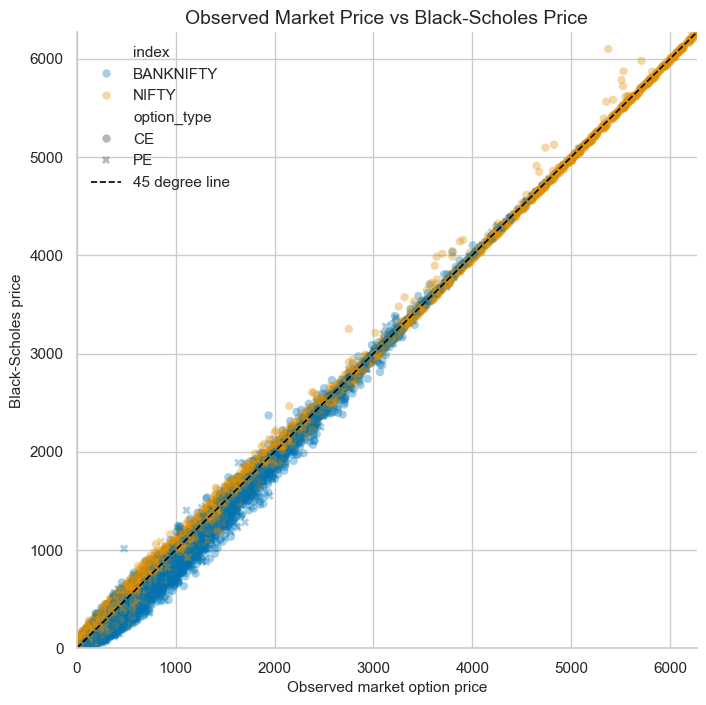

In [63]:
# ---------------------------------------------------------------
# Observed vs Black-Scholes price
# ---------------------------------------------------------------

plot_df = sample_for_plot(df[["index", "option_type", "pre_post_period", "option_price", "bs_price"]].dropna())

fig, ax = plt.subplots(figsize=(8, 8))
sns.scatterplot(
    data=plot_df,
    x="option_price",
    y="bs_price",
    hue="index",
    style="option_type",
    alpha=0.35,
    linewidth=0,
    ax=ax,
)

price_limit = np.nanpercentile(plot_df[["option_price", "bs_price"]].to_numpy(), 99)
ax.plot([0, price_limit], [0, price_limit], color="black", linewidth=1.2, linestyle="--", label="45 degree line")
ax.set_xlim(0, price_limit)
ax.set_ylim(0, price_limit)
ax.set_title("Observed Market Price vs Black-Scholes Price")
ax.set_xlabel("Observed market option price")
ax.set_ylabel("Black-Scholes price")
ax.legend(loc="upper left")
save_figure("observed_vs_black_scholes_price", fig)
plt.show()


Saved figure: c:\Users\sanka\OneDrive\Documents\Derivatives\Data\Raw\Output\figures\pricing_error_distribution.png


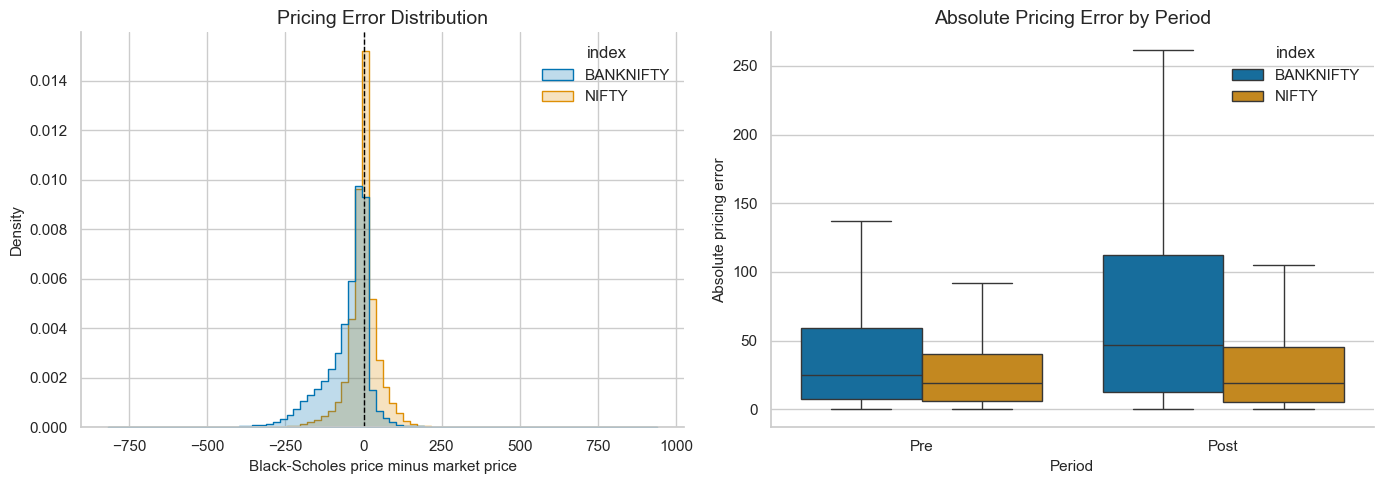

In [64]:
# ---------------------------------------------------------------
# Pricing error distribution
# ---------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="pricing_error",
    hue="index",
    bins=80,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[0],
)
axes[0].axvline(0, color="black", linewidth=1.0, linestyle="--")
axes[0].set_title("Pricing Error Distribution")
axes[0].set_xlabel("Black-Scholes price minus market price")

sns.boxplot(
    data=pricing_reporting_df,
    x="pre_post_period",
    y="absolute_pricing_error",
    hue="index",
    showfliers=False,
    ax=axes[1],
)
axes[1].set_title("Absolute Pricing Error by Period")
axes[1].set_xlabel("Period")
axes[1].set_ylabel("Absolute pricing error")

fig.tight_layout()
save_figure("pricing_error_distribution", fig)
plt.show()


Saved figure: c:\Users\sanka\OneDrive\Documents\Derivatives\Data\Raw\Output\figures\implied_volatility_distribution.png


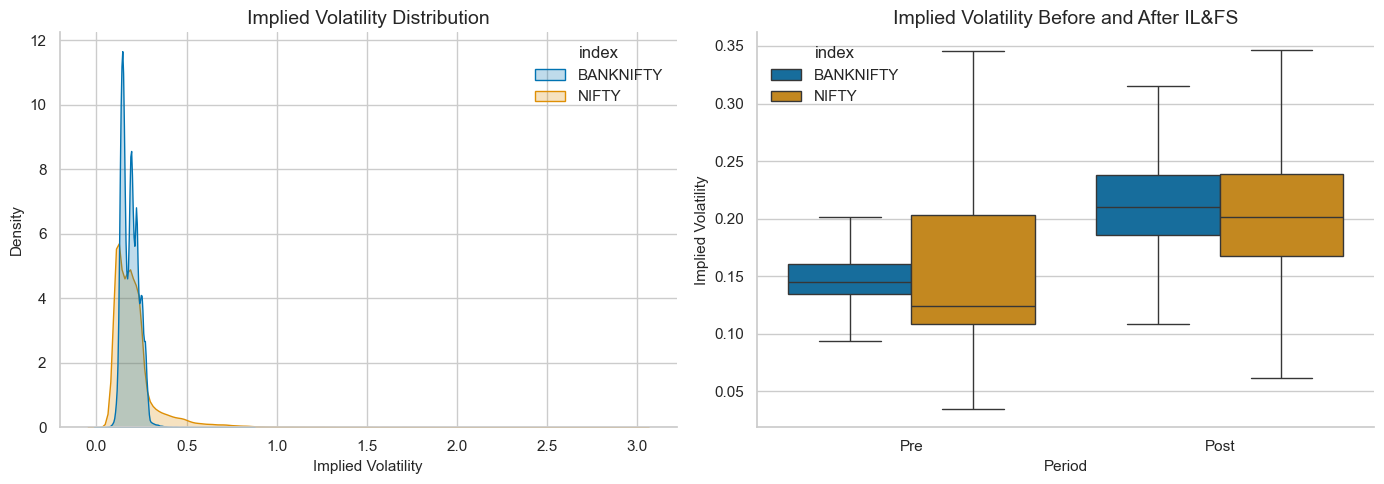

In [65]:
# ---------------------------------------------------------------
# Implied Volatility Distribution
# ---------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribution of implied volatility
sns.kdeplot(
    data=df.dropna(subset=["implied_volatility"]),
    x="implied_volatility",
    hue="index",
    common_norm=False,
    fill=True,
    alpha=0.25,
    ax=axes[0],
)

axes[0].set_title("Implied Volatility Distribution")
axes[0].set_xlabel("Implied Volatility")
axes[0].set_ylabel("Density")

# Implied volatility before and after IL&FS
sns.boxplot(
    data=df,
    x="pre_post_period",
    y="implied_volatility",
    hue="index",
    showfliers=False,
    ax=axes[1],
)

axes[1].set_title("Implied Volatility Before and After IL&FS")
axes[1].set_xlabel("Period")
axes[1].set_ylabel("Implied Volatility")

fig.tight_layout()

save_figure("implied_volatility_distribution", fig)

plt.show()

Saved figure: c:\Users\sanka\OneDrive\Documents\Derivatives\Data\Raw\Output\figures\greeks_distribution.png


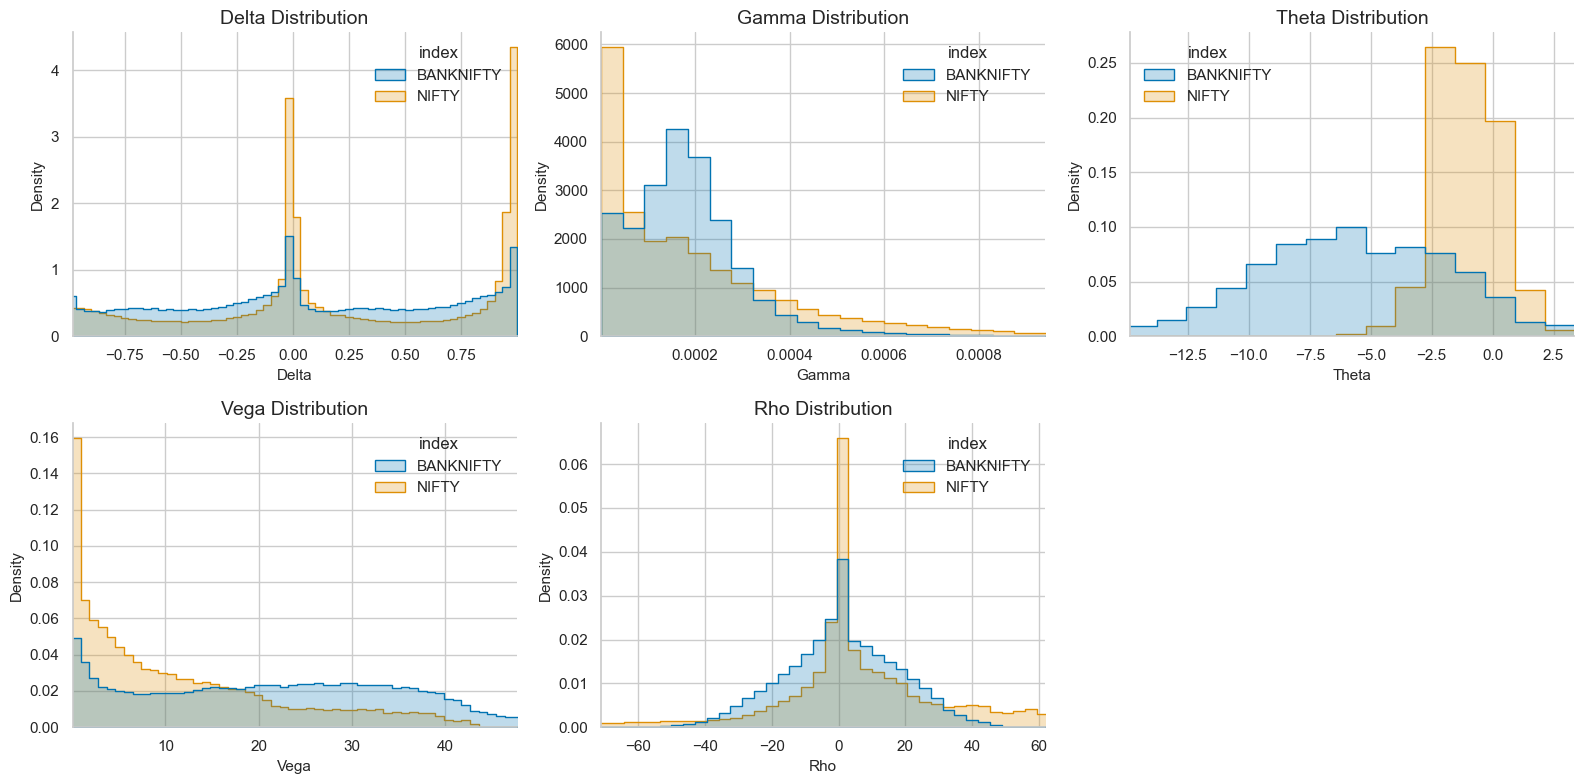

In [66]:
# ---------------------------------------------------------------
# Greeks Distribution
# ---------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for axis, greek in zip(axes, GREEK_COLUMNS):
    sns.histplot(
        data=df,
        x=greek,
        hue="index",
        bins=60,
        stat="density",
        common_norm=False,
        element="step",
        ax=axis,
    )

    finite_values = clean_numeric_sample(df[greek])
    if len(finite_values) > 0:
        lower, upper = finite_values.quantile([0.01, 0.99])
        if np.isfinite(lower) and np.isfinite(upper) and lower < upper:
            axis.set_xlim(lower, upper)

    axis.set_title(f"{greek.title()} Distribution")
    axis.set_xlabel(greek.title())
    axis.set_ylabel("Density")

# Hide any unused subplot(s)
for axis in axes[len(GREEK_COLUMNS):]:
    axis.axis("off")

fig.tight_layout()

save_figure("greeks_distribution", fig)

plt.show()

In [28]:
print(pricing_performance_by_moneyness.columns.tolist())

['moneyness_band', 'observations', 'mean_market_price', 'mean_bs_price', 'mean_error', 'bias', 'mean_pricing_error', 'mae', 'rmse', 'mape_percent', 'median_error', 'median_pricing_error', 'std_error', 'max_absolute_error', 'mean_relative_pricing_error', 'median_relative_pricing_error']


Saved figure: c:\Users\sanka\OneDrive\Documents\Derivatives\Data\Raw\Output\figures\hedge_effectiveness.png


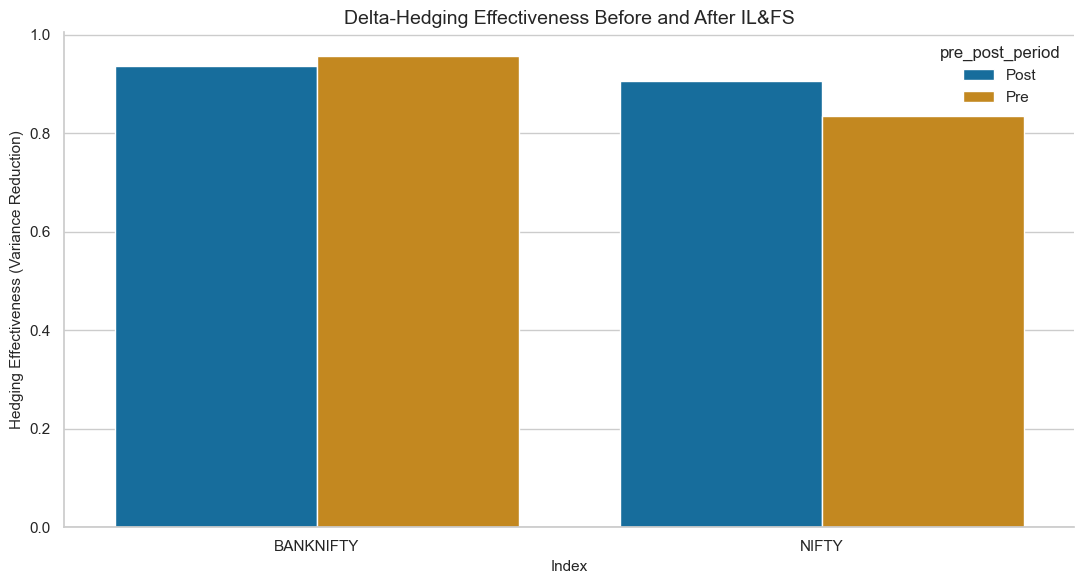

In [67]:
# ---------------------------------------------------------------
# Hedging Effectiveness
# ---------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 6))

sns.barplot(
    data=hedging_summary_by_index_period,
    x="index",
    y="hedging_effectiveness",
    hue="pre_post_period",
    errorbar=None,
    ax=ax,
)

ax.axhline(0, color="black", linewidth=0.8)

ax.set_title("Delta-Hedging Effectiveness Before and After IL&FS")
ax.set_xlabel("Index")
ax.set_ylabel("Hedging Effectiveness (Variance Reduction)")

fig.tight_layout()

save_figure("hedge_effectiveness", fig)

plt.show()

Saved figure: c:\Users\sanka\OneDrive\Documents\Derivatives\Data\Raw\Output\figures\event_study_plots.png


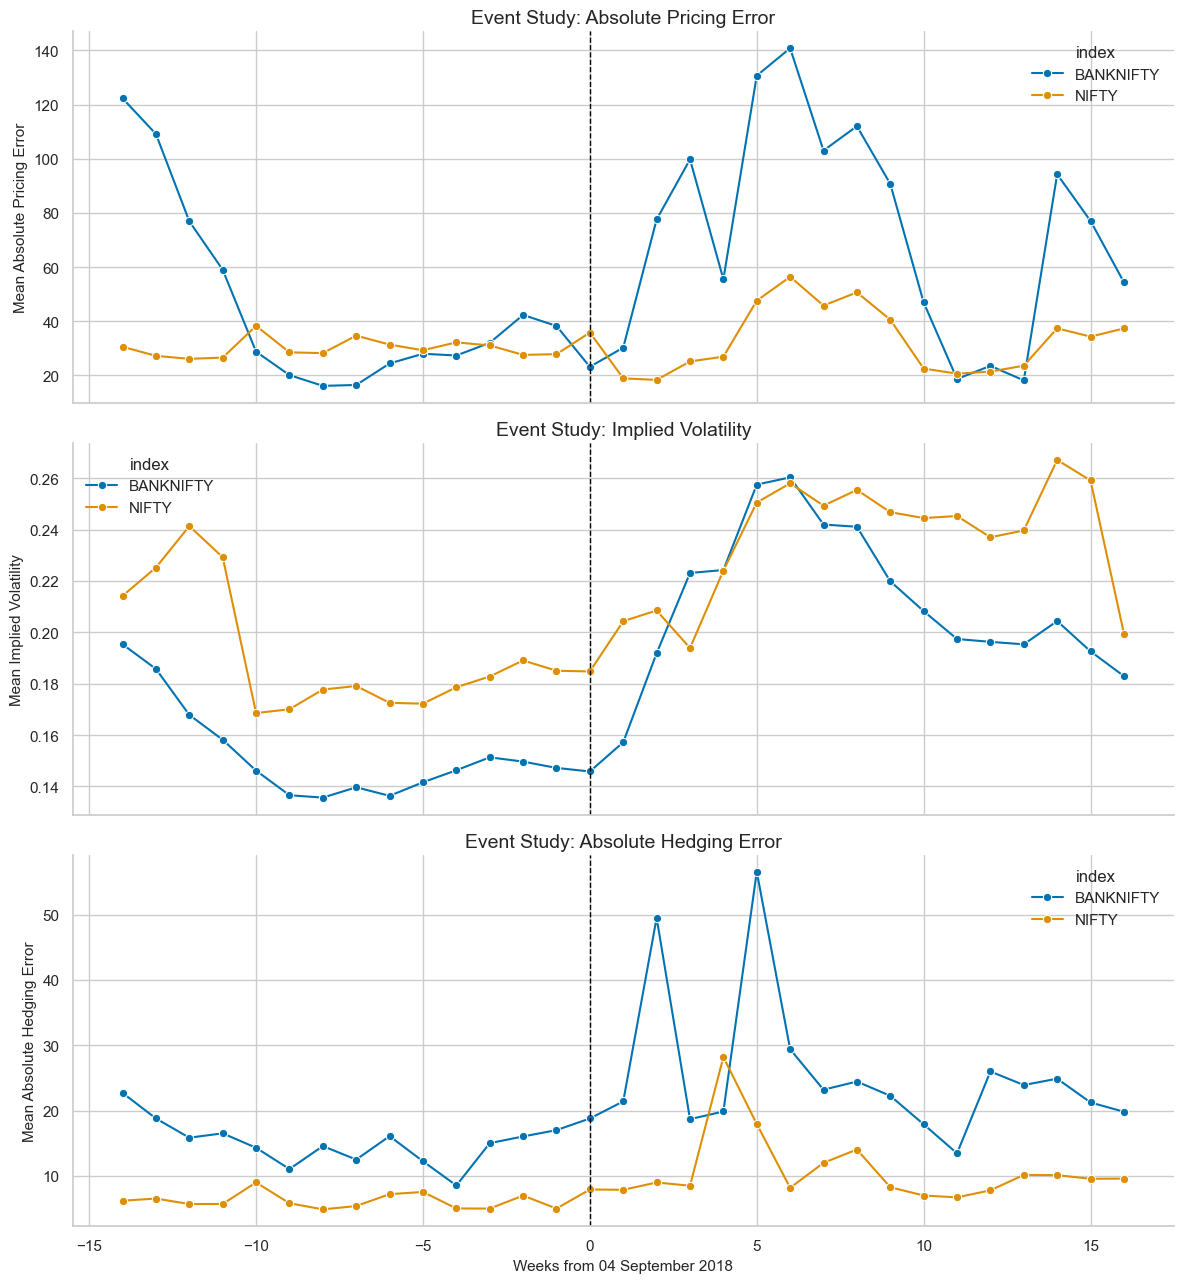

In [68]:
# ---------------------------------------------------------------
# Event Study
# ---------------------------------------------------------------

fig, axes = plt.subplots(3, 1, figsize=(12, 13), sharex=True)

# Absolute pricing error
sns.lineplot(
    data=event_study_weekly,
    x="weeks_from_event",
    y="mean_absolute_pricing_error",
    hue="index",
    marker="o",
    ax=axes[0],
)

axes[0].axvline(0, color="black", linewidth=1.0, linestyle="--")
axes[0].set_title("Event Study: Absolute Pricing Error")
axes[0].set_ylabel("Mean Absolute Pricing Error")

# Implied volatility
sns.lineplot(
    data=event_study_weekly,
    x="weeks_from_event",
    y="mean_implied_volatility",
    hue="index",
    marker="o",
    ax=axes[1],
)

axes[1].axvline(0, color="black", linewidth=1.0, linestyle="--")
axes[1].set_title("Event Study: Implied Volatility")
axes[1].set_ylabel("Mean Implied Volatility")

# Absolute hedging error
sns.lineplot(
    data=event_study_weekly,
    x="weeks_from_event",
    y="mean_absolute_hedging_error",
    hue="index",
    marker="o",
    ax=axes[2],
)

axes[2].axvline(0, color="black", linewidth=1.0, linestyle="--")
axes[2].set_title("Event Study: Absolute Hedging Error")
axes[2].set_xlabel("Weeks from 04 September 2018")
axes[2].set_ylabel("Mean Absolute Hedging Error")

fig.tight_layout()

save_figure("event_study_plots", fig)

plt.show()

Saved figure: c:\Users\sanka\OneDrive\Documents\Derivatives\Data\Raw\Output\figures\iv_smile.png


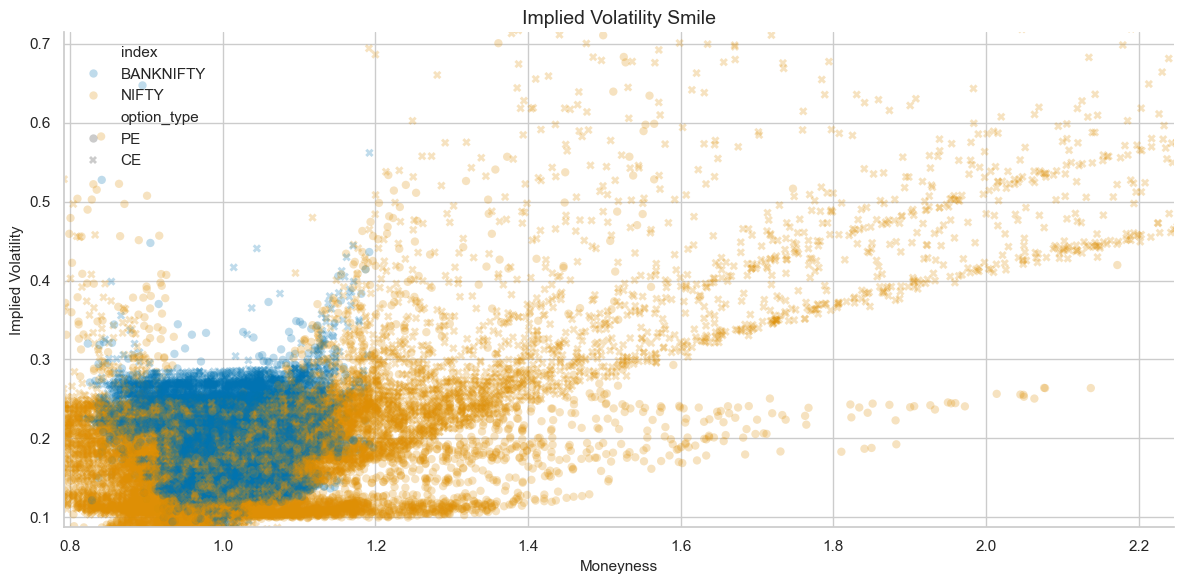

In [69]:
# ---------------------------------------------------------------
# Implied Volatility Smile
# ---------------------------------------------------------------

iv_plot_df = df.dropna(subset=["implied_volatility", "moneyness"])

smile_df = sample_for_plot(iv_plot_df, max_rows=30_000)

fig, ax = plt.subplots(figsize=(12, 6))

sns.scatterplot(
    data=smile_df,
    x="moneyness",
    y="implied_volatility",
    hue="index",
    style="option_type",
    alpha=0.25,
    linewidth=0,
    ax=ax,
)

ax.set_xlim(*iv_plot_df["moneyness"].quantile([0.01, 0.99]))
ax.set_ylim(*iv_plot_df["implied_volatility"].quantile([0.01, 0.99]))

ax.set_title("Implied Volatility Smile")
ax.set_xlabel("Moneyness")
ax.set_ylabel("Implied Volatility")

fig.tight_layout()

save_figure("iv_smile", fig)

plt.show()

Saved figure: c:\Users\sanka\OneDrive\Documents\Derivatives\Data\Raw\Output\figures\correlation_heatmap.png


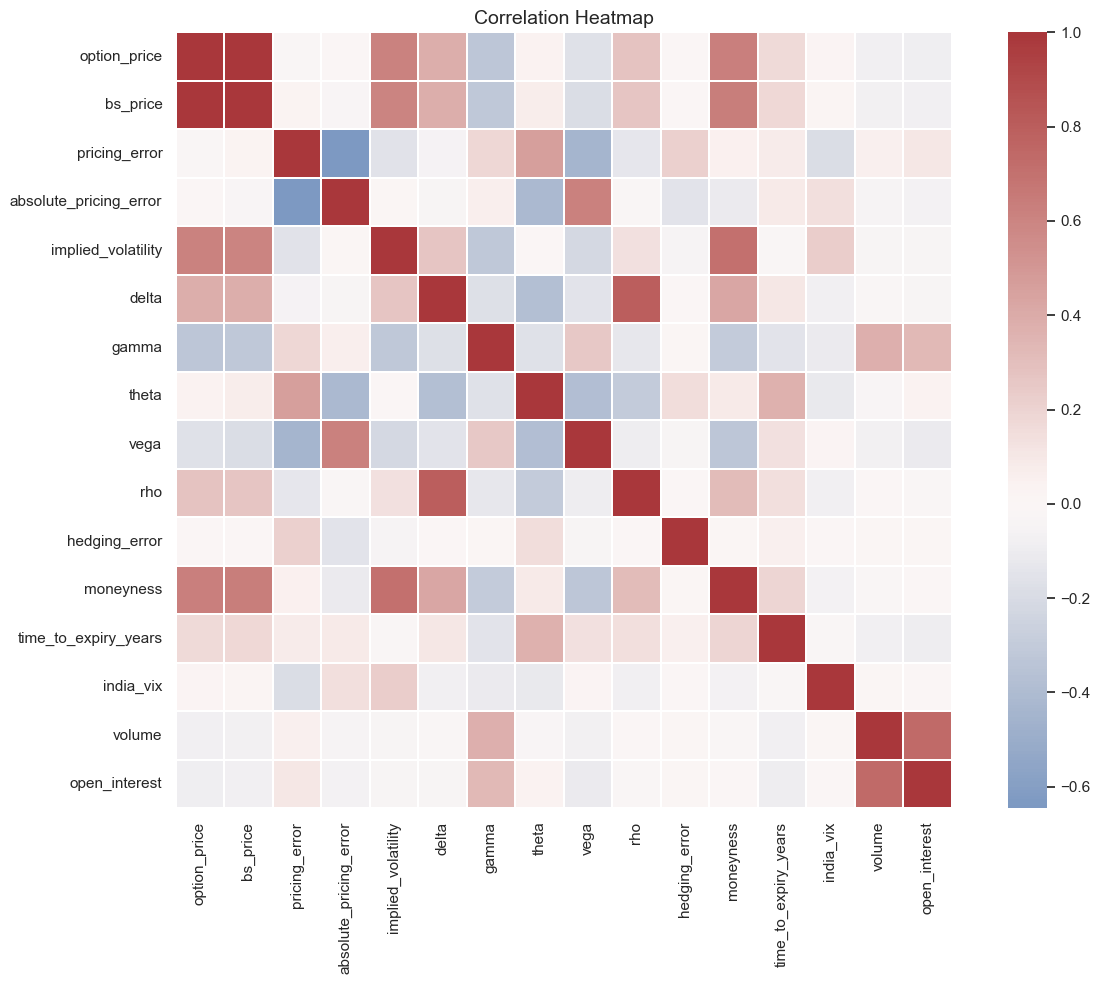

In [70]:
# ---------------------------------------------------------------
# Correlation Heatmap
# ---------------------------------------------------------------

correlation_columns = [
    "option_price",
    "bs_price",
    "pricing_error",
    "absolute_pricing_error",
    "implied_volatility",
    "delta",
    "gamma",
    "theta",
    "vega",
    "rho",
    "hedging_error",
    "moneyness",
    "time_to_expiry_years",
    "india_vix",
    "volume",
    "open_interest",
]

correlation_matrix = (
    df[correlation_columns]
    .replace([np.inf, -np.inf], np.nan)
    .corr()
)

fig, ax = plt.subplots(figsize=(13, 10))

sns.heatmap(
    correlation_matrix,
    cmap="vlag",
    center=0,
    linewidths=0.3,
    square=True,
    ax=ax,
)

ax.set_title("Correlation Heatmap")

fig.tight_layout()

save_figure("correlation_heatmap", fig)

plt.show()

## SECTION 10 - Summary Tables

The following tables are assembled for dissertation reporting and exported in
Section 11.


In [57]:
# ---------------------------------------------------------------
# Summary Tables
# ---------------------------------------------------------------

# Descriptive statistics
descriptive_statistics = (
    df[
        [
            "option_price",
            "bs_price",
            "pricing_error",
            "absolute_pricing_error",
            "relative_pricing_error",
            "implied_volatility",
            "delta",
            "gamma",
            "theta",
            "vega",
            "rho",
            "option_pnl",
            "stock_hedge_pnl",
            "cash_pnl",
            "hedged_pnl",
            "hedging_error",
            "absolute_hedging_error",
            "hedged_portfolio_return",
            "unhedged_option_return",
            "volume",
            "open_interest",
            "moneyness",
            "time_to_expiry_years",
            "india_vix",
        ]
    ]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    .T
    .reset_index()
    .rename(columns={"index": "variable"})
)

# Optional correlation matrix (only if using the correlation heatmap)
correlation_columns = [
    "option_price",
    "bs_price",
    "pricing_error",
    "absolute_pricing_error",
    "implied_volatility",
    "delta",
    "gamma",
    "theta",
    "vega",
    "rho",
    "hedging_error",
    "moneyness",
    "time_to_expiry_years",
    "india_vix",
    "volume",
    "open_interest",
]

correlation_matrix_export = (
    df[correlation_columns]
    .replace([np.inf, -np.inf], np.nan)
    .corr()
    .reset_index()
    .rename(columns={"index": "variable"})
)

# ---------------------------------------------------------------
# Final table registry
# ---------------------------------------------------------------

table_registry = {
    "dataset_validation": dataset_validation,
    "load_summary": load_summary,
    "descriptive_statistics": descriptive_statistics,
    "pricing_performance_by_pre_post": pricing_performance_by_pre_post,
    "hedging_summary_overall": hedging_summary_overall,
    "event_study_summary": event_study_summary,
    "correlation_matrix": correlation_matrix_export,      # Remove this line if not using the heatmap
    "statistical_test_summary": statistical_test_summary,
    "ols_regression_summary": ols_regression_summary,
}

# ---------------------------------------------------------------
# Preview
# ---------------------------------------------------------------

print(f"Prepared {len(table_registry)} summary tables.")

display(descriptive_statistics.head(20))

Prepared 9 summary tables.


,variable,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
0,option_price,"248,227.000000","1,024.296959","1,279.013664",0.050000,0.050000,1.350000,93.950000,570.000000,"1,485.550000","3,563.785000","6,202.737000","8,225.650000"
1,bs_price,"248,227.000000",998.253068,"1,279.565843",0.000000,0.000138,0.311642,77.537671,525.344230,"1,450.020534","3,550.766108","6,191.527667","8,218.886201"
2,pricing_error,"248,227.000000",-26.043891,68.761591,-816.391383,-251.812777,-164.584992,-46.572178,-9.955321,3.337870,62.085549,121.449093,938.374840
3,absolute_pricing_error,"248,227.000000",46.009550,57.354652,0.000044,0.049789,0.614600,7.267561,24.793266,61.804698,169.310513,258.160964,938.374840
4,relative_pricing_error,"248,227.000000",0.003331,0.858244,-1.000000,-0.999827,-0.843388,-0.196344,-0.016801,0.013557,0.827805,3.145181,29.494698
5,implied_volatility,"233,004.000000",0.200950,0.121738,0.000100,0.087405,0.106262,0.141069,0.182908,0.225294,0.347648,0.714604,3.016305
6,delta,"233,004.000000",0.128082,0.596732,-1.000000,-0.982953,-0.884317,-0.284320,0.021575,0.709365,0.985407,0.996404,0.999852
7,gamma,"233,004.000000",0.000200,0.000194,0.000000,0.000001,0.000006,0.000069,0.000163,0.000259,0.000557,0.000941,0.002766
8,theta,"233,004.000000",-3.440204,3.906501,-67.669442,-14.876241,-10.893393,-5.794548,-2.156781,-0.644183,1.000233,3.338619,5.808889
9,vega,"233,004.000000",16.746053,13.315167,0.000000,0.056349,0.334864,4.560392,14.395822,27.326014,40.284051,47.606713,55.590349


## SECTION 11 - Export

This section saves:

- Final dataframe: `analysis_dataset_final.csv`
- Figures: `figures/*.png`
- Summary tables: `tables/*.csv`
- Final review report: `final_review_report.md`

The final dataframe includes the original validated columns plus the required
analysis outputs: Black-Scholes prices, implied volatility, Greeks, hedging
metrics, and pricing-error variables.


In [61]:
# ---------------------------------------------------------------
# Export Summary Tables
# ---------------------------------------------------------------

exported_tables = {}

for table_name, table in table_registry.items():
    output_path = TABLE_DIR / f"{table_name}.csv"
    table.to_csv(output_path, index=False)
    exported_tables[table_name] = output_path

exported_table_summary = pd.DataFrame(
    {
        "Table": list(exported_tables.keys()),
        "File": [path.name for path in exported_tables.values()],
    }
)

print(f"Exported {len(exported_tables)} summary tables.")

display(exported_table_summary)

Exported 9 summary tables.


,Table,File
0,dataset_validation,dataset_validation.csv
1,load_summary,load_summary.csv
2,descriptive_statistics,descriptive_statistics.csv
3,pricing_performance_by_pre_post,pricing_performance_by_pre_post.csv
4,hedging_summary_overall,hedging_summary_overall.csv
5,event_study_summary,event_study_summary.csv
6,correlation_matrix,correlation_matrix.csv
7,statistical_test_summary,statistical_test_summary.csv
8,ols_regression_summary,ols_regression_summary.csv


In [62]:
# ---------------------------------------------------------------
# Export Final Analytical DataFrame
# ---------------------------------------------------------------
# The original CSV remains unchanged. This output is the analysis-ready
# dataset created by the notebook.

df.to_csv(OUTPUT_DATA_FILE, index=False)

export_summary = pd.DataFrame(
    {
        "Output": [
            "Final Analytical DataFrame",
            "Figures",
            "Summary Tables",
        ],
        "Location": [
            str(OUTPUT_DATA_FILE),
            str(FIGURE_DIR),
            str(TABLE_DIR),
        ],
        "Count": [
            len(df),
            len(figure_registry),
            len(exported_tables),
        ],
    }
)

display(export_summary)

NOTEBOOK_RUN_FINISHED = pd.Timestamp.now()

print(f"Notebook run finished: {NOTEBOOK_RUN_FINISHED:%Y-%m-%d %H:%M:%S}")
print(f"Elapsed notebook wall time: {NOTEBOOK_RUN_FINISHED - NOTEBOOK_RUN_STARTED}")
print("Analysis complete.")

,Output,Location,Count
0,Final Analytical DataFrame,c:\Users\sanka\OneDrive\Documents\Derivatives\...,248227
1,Figures,c:\Users\sanka\OneDrive\Documents\Derivatives\...,29
2,Summary Tables,c:\Users\sanka\OneDrive\Documents\Derivatives\...,9


Notebook run finished: 2026-07-29 14:21:53
Elapsed notebook wall time: 0 days 02:26:03.289266
Analysis complete.
